# Computational Linear Algebra: PCA Homework

## Francesco Della Santa, Computational Linear Algebra for Large Scale Problems, Politecnico di Torino

**ATTENTION:** the presentation of this homework to the students happened during the laboratory of 20/11/2026. The recording of that laboratory is available on the web page of the course. *Before asking any question to the teacher*, please read carefully this notebook and view the recorded laboratory of 20/11/2026.

**ATTENTION:** We strongly suggest to view the recorded laboratory of 20/11/2026, since it contains a simulation of this homework.

## Guidelines

**ATTENTION:** the homework evaluation depend also on the level of the homework's compliance with the following guidelines.

### General Guidelines
1. The assignment can be done at most in **teams of 3 people**;
2. **People in the same team are expected to take the exam in the same call, the same day, alltogether**. If a team member fails the exam or rejects the mark he/she can take the exam in another call maintaining the same report.
3. The part of exam related to PCA and $k$-Means will consist in:
   1. A **presentation of 10 minutes** of the homework (*12 minutes for teams of three people*), made *using directly the printed PDF of this notebook*. **No presentations, slides, or similar tools are allowed**.
   2. After the presentation, there will be a discussion with the teacher, asking **questions to the team members related to PCA and $k$-Means**.

    For more details, see the *Discussion Guidelines* below.

4. The final score of this part of exam depends both on the homework contents and the defense; then, **people belonging to the same team can obtain different scores**, according to their defense performance.
5. **python modules not included in the list of the course cannot be used in the homework**, unless you obtain the permission from the teacher.

### Guidelines for Submitting the Homework
1. You are expected to submit, though *"Consegna Elaborati"* on the page of the cours, **a single zip file per group (and not per person)**, containing:
    1. This jupyter notebook of the homework, filled with your codes, comments and results;
    2. The PDF report obtained by printing the notebook. **This PDF will be the one to be used during the presentation**.
2. The **zip file must have the same filename of the notebook, exactly like the PDF**. This name consist in
   $$
   \texttt{HWpca\_Surname1\_Surname2\_Surname3}
   $$
   where the surnames are in **alphabetical order and without whitespaces** (remove surnames for teams with less than 3 members).
4. If you do not submit the homework following these rules, the submission *could be considered not valid*.
5. The deadline for submitting the homework is **the same deadline for registering to the exam**.

### Discussion Guidelines

1. For the discussion of the report, **the team must bring a PC** with the notebook ready to be run, in case of needs, and the **PDF of the report**.
2. The team will have **10 minutes to present** (*12 minutes for teams of three people*) the results contained in the report, **by using the PDF**. After the presentation, there will be a discussion with the teacher, asking **questions to the team members that will involve also the theory behind the methods**.
3. The team members will discuss the report directly commenting on it (i.e., on the PDF file), **without running the code, supporting slides, or other kind of summarizing presentations**.

## The Problem of the Homework

The dataset used in this homework is the *Young-People-Survey* (YPS) dataset; the dataset origin dates back to 2013, when were asked to the **students** of the Statistics class at the Faculty of Social and Economic Sciences of the University of Bratislava to invite their friends to **participate in a survey**. The questions in the survey concern eight different categories of questions:
1. Music preferences (19 items)
2. Movie preferences (12 items)
3. Hobbies & interests (32 items)
4. Phobias (10 items)
5. Health habits (3 items)
6. Personality traits, views on life, & opinions (57 items)
7. Spending habits (7 items)
8. Demographics (10 items)

**N.B.:** Excluding the "*Demographics*" group, almost all the answers consist of a rating between 1 and 5. The non-rating answers are instead characterized by *categorical values; however, these values can be considered ordered*...


Moreover, we can identify *three types of questions* that group "similar" categories:
1. Entertainment questions: music preferences, movie preferences, hobby & interests (63 items);
2. Personality questions: phobias, health habits, personality traits (etc.), spending habits (77 items);
3. Demographics questions: demographics (10 items).

### The Files

Inside the homework’s folder, excluding the notebook, you can find two files:
- *responses_hw.csv*: the data file with all the responses of the people to the survey (each row is a person, each column is a question);
- *columns_hw.csv*: a file that show the original question in the survey and the column name in responses hw.csv.

Some characteristics to be known concerning the dataset are:
- The data file responses_hw.csv consists of 674 rows and 150 columns (139 integer and 11 categorical).
- The dataset is **already cleansed**.


### The Problem - Simulating a Real World Case Scenario

Given the YPS dataset, you must use the *Principal Component Analysis* (PCA) to reduce the dimensionality of the problem and, then, identify meaningful clusters of people (if existing) using the $k$-Means algorithm. Detailed instructions for the exercises are written at the beginning of each exercise.

With this homework we want to *simulate an hypothetical situation where a company wants to identify meaningful profiles of their customers*. Typically, all the information gathered with a customer survey must be summarized with few and easily-comprehensible concepts to help the managers with future decisions. Then, in these situations, very often the number $m$ of chosen *Principal Components* (PCs) is very low, giving more importance to the dimensionality reduction than the preservation of the information.


## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of other students if you are less than three members**.

**Academic Year:** 2026/2027

### Team Members (Alphabetical Order):
1. Barbi, Giulia (StudentID1);
2. Surname2, Name2 (StudentID2).
3. Surname3, Name3 (StudentID3).

Now, fill the python list below with the Student IDs of the team

In [3]:
StudentIDs = [376697,371242,370609]  # <-------- Fill this list with Student IDs of the team

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [4]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Shopping centres
Branded clothing
Spending on looks
Spending on gadgets
Smoking
Healthy eating
History
Psychology
Politics
Mathematics
Biology
Reading
Geography
Medicine
Law
Cars
Art exhibitions
Religion
Dancing
Writing
Celebrities
Shopping
Theatre
Fun with friends
Pets
Movies
Horror
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Documentary
Western
Action
Music
Slow songs or fast songs
Dance
Country
Classical music
Rock
Punk
Hiphop, Rap
Reggae, Ska
Techno, Trance
Opera
Daily events
Prioritising workload
Writing notes
Workaholism
Final judgement
Keeping promises
Loss of interest
Funniness
Fake
Criminal damage
Self-criticism
Empathy
Eating to survive
Giving
Loneliness
Cheating in school
Health
Charity
Punctuality
Lying
New environment
Mood swings
Appearence and gestures
Socializing
Achievements
Responding to a serious letter
Children
Assertiveness
Getting angry
Knowing the right people
Public speaking
Unpopularit

,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
472,3,2,3,2,4,tried smoking,4,5,5,5,...,21,187,73,4,male,right,college/bachelor degree,no,city,house/bungalow
476,4,3,2,3,2,current smoker,3,3,3,1,...,26,168,65,3,female,right,college/bachelor degree,no,village,house/bungalow
121,3,5,4,4,2,tried smoking,3,3,4,5,...,20,168,60,1,female,right,college/bachelor degree,yes,city,block of flats
198,2,5,3,4,4,former smoker,2,5,5,4,...,20,170,70,1,female,right,college/bachelor degree,no,city,block of flats
487,3,4,4,1,5,never smoked,2,4,1,3,...,29,183,111,1,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,1,4,4,4,4,tried smoking,3,2,2,2,...,22,167,50,1,female,right,secondary school,no,city,block of flats
130,5,3,5,3,3,tried smoking,3,5,5,3,...,22,182,75,1,male,right,secondary school,no,city,block of flats
461,3,1,1,1,4,tried smoking,3,5,3,1,...,23,162,65,1,female,right,college/bachelor degree,no,city,block of flats
455,3,3,3,3,3,current smoker,3,3,4,3,...,23,170,60,1,female,right,secondary school,no,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Storm,Heights,Spiders,Rats,Ageing,Dangerous dogs
472,3,2,3,2,4,tried smoking,4,5,5,5,...,5,3,3,few hours a day,2,1,3,2,1,2
476,4,3,2,3,2,current smoker,3,3,3,1,...,4,3,2,few hours a day,3,3,2,5,3,5
121,3,5,4,4,2,tried smoking,3,3,4,5,...,5,5,1,few hours a day,2,4,4,5,4,4
198,2,5,3,4,4,former smoker,2,5,5,4,...,5,2,3,few hours a day,1,5,4,1,3,2
487,3,4,4,1,5,never smoked,2,4,1,3,...,1,3,4,few hours a day,2,2,2,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,1,4,4,4,4,tried smoking,3,2,2,2,...,3,1,1,most of the day,4,4,3,3,3,4
130,5,3,5,3,3,tried smoking,3,5,5,3,...,4,3,4,few hours a day,2,2,5,1,3,5
461,3,1,1,1,4,tried smoking,3,5,3,1,...,1,4,3,few hours a day,1,1,3,3,3,1
455,3,3,3,3,3,current smoker,3,3,4,3,...,3,3,3,few hours a day,1,1,1,1,1,1



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
472,21,187,73,4,male,right,college/bachelor degree,no,city,house/bungalow
476,26,168,65,3,female,right,college/bachelor degree,no,village,house/bungalow
121,20,168,60,1,female,right,college/bachelor degree,yes,city,block of flats
198,20,170,70,1,female,right,college/bachelor degree,no,city,block of flats
487,29,183,111,1,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...
613,22,167,50,1,female,right,secondary school,no,city,block of flats
130,22,182,75,1,male,right,secondary school,no,city,block of flats
461,23,162,65,1,female,right,college/bachelor degree,no,city,block of flats
455,23,170,60,1,female,right,secondary school,no,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [5]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
#Ex 1
from sklearn.preprocessing import MinMaxScaler

#Ex 2
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#Ex 4
from sklearn.cluster import KMeans


#Ex 6
from sklearn.metrics import silhouette_score,silhouette_samples


## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [6]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE MinMaxScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
Our subset contains four categorical features: *Smoking*, *Punctuality*, *Lying* and *Internet usage*. As stated in the homework description, their categories are totally ordered (e.g., *Internet usage* goes from "less than an hour a day" to "most of the day"), so we apply an **Ordinal Encoding**, mapping each category to an integer that respects its natural order.

We prefer it to One-Hot Encoding for three reasons. First, the order is real information about the participants, while One-Hot would lose it, treating all categories as equally distant. Second, One-Hot would add 10 extra binary columns, increasing the dimensionality, against the goal of PCA. Third, all features become ordered "rank values", like the 1–5 ratings of the other answers, which makes the MinMax scaling a coherent choice.

However, ordinal encoding assumes that the distance between any two consecutive categories is always the same, even though in reality it may differ.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
We apply the **MinMaxScaler**, which rescales each feature independently into the range [0, 1], using $(x - x_{min}) / (x_{max} - x_{min})$. This scaler is suitable for survey data like ours, where all features are rank values with similar scales.

The main effect is that all features become comparable, since they share the same range regardless of their number of levels (e.g., 1–5 ratings and 3-level categories). However, unlike the StandardScaler, it does not force all features to have unit variance: each feature keeps its own variance, reflecting how much the participants' answers differ. Therefore, the PCA will still give more importance to the questions on which people disagree the most. A side effect is that features with fewer levels (e.g., *Punctuality* and *Internet usage*, with range 2) are divided by a smaller range, so their relative variance may increase compared to the 1–5 ratings (range 4).

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [7]:
# Ordinal encoding of the categorical features (categories are totally ordered)
# each category is mapped to an integer that respects its natural order. 
ordinal_maps = {
    'Smoking': {
        'never smoked': 1, 
        'tried smoking': 2,
        'former smoker': 3,
        'current smoker': 4
        },
    'Punctuality': {
        'late': 1, 
        'on time': 2, 
        'early': 3
        },
    'Lying': {
        'never': 1, 
        'only to avoid hurting someone': 2,
        'sometimes': 3, 
        'everytime it suits me': 4
        },
    'Internet usage': {
        'less than an hour a day': 1, 
        'few hours a day': 2,
        'most of the day': 3
        }
}

# Copy the original features, so that responses_ft is not modified
responses_ft_enc = responses_ft.copy()

# Replace the text categories with their integer values
# (only for the categorical columns present in our personal subset)
for col, mapping in ordinal_maps.items():
    if col in responses_ft_enc.columns:
        responses_ft_enc[col] = responses_ft_enc[col].map(mapping)

# Apply MinMax scaling
# rescale each feature into [0,1] using (x - min) / (max - min)
scaler = MinMaxScaler()

responses_ft_pp = pd.DataFrame(
    scaler.fit_transform(responses_ft_enc),
    columns=responses_ft_enc.columns,
    index=responses_ft_enc.index
)

print(f'Encoded dataset shape: {responses_ft_enc.shape}')
display(responses_ft_enc)
display(responses_ft_pp)


# Variance of each feature before and after scaling
variances = pd.DataFrame({'Encoded': responses_ft_enc.var(),
                          'MinMax scaled': responses_ft_pp.var()})

print('*** VARIANCE OF EACH FEATURE BEFORE AND AFTER THE MINMAX SCALING')
print('Features are sorted by increasing variance after scaling')
display(variances.sort_values('MinMax scaled'))

Encoded dataset shape: (506, 93)


,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Storm,Heights,Spiders,Rats,Ageing,Dangerous dogs
472,3,2,3,2,4,2,4,5,5,5,...,5,3,3,2,2,1,3,2,1,2
476,4,3,2,3,2,4,3,3,3,1,...,4,3,2,2,3,3,2,5,3,5
121,3,5,4,4,2,2,3,3,4,5,...,5,5,1,2,2,4,4,5,4,4
198,2,5,3,4,4,3,2,5,5,4,...,5,2,3,2,1,5,4,1,3,2
487,3,4,4,1,5,1,2,4,1,3,...,1,3,4,2,2,2,2,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,1,4,4,4,4,2,3,2,2,2,...,3,1,1,3,4,4,3,3,3,4
130,5,3,5,3,3,2,3,5,5,3,...,4,3,4,2,2,2,5,1,3,5
461,3,1,1,1,4,2,3,5,3,1,...,1,4,3,2,1,1,3,3,3,1
455,3,3,3,3,3,4,3,3,4,3,...,3,3,3,2,1,1,1,1,1,1


,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Storm,Heights,Spiders,Rats,Ageing,Dangerous dogs
472,0.50,0.25,0.50,0.25,0.75,0.333333,0.75,1.00,1.00,1.00,...,1.00,0.50,0.50,0.5,0.25,0.00,0.50,0.25,0.00,0.25
476,0.75,0.50,0.25,0.50,0.25,1.000000,0.50,0.50,0.50,0.00,...,0.75,0.50,0.25,0.5,0.50,0.50,0.25,1.00,0.50,1.00
121,0.50,1.00,0.75,0.75,0.25,0.333333,0.50,0.50,0.75,1.00,...,1.00,1.00,0.00,0.5,0.25,0.75,0.75,1.00,0.75,0.75
198,0.25,1.00,0.50,0.75,0.75,0.666667,0.25,1.00,1.00,0.75,...,1.00,0.25,0.50,0.5,0.00,1.00,0.75,0.00,0.50,0.25
487,0.50,0.75,0.75,0.00,1.00,0.000000,0.25,0.75,0.00,0.50,...,0.00,0.50,0.75,0.5,0.25,0.25,0.25,0.00,0.00,0.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,0.00,0.75,0.75,0.75,0.75,0.333333,0.50,0.25,0.25,0.25,...,0.50,0.00,0.00,1.0,0.75,0.75,0.50,0.50,0.50,0.75
130,1.00,0.50,1.00,0.50,0.50,0.333333,0.50,1.00,1.00,0.50,...,0.75,0.50,0.75,0.5,0.25,0.25,1.00,0.00,0.50,1.00
461,0.50,0.00,0.00,0.00,0.75,0.333333,0.50,1.00,0.50,0.00,...,0.00,0.75,0.50,0.5,0.00,0.00,0.50,0.50,0.50,0.00
455,0.50,0.50,0.50,0.50,0.50,1.000000,0.50,0.50,0.75,0.50,...,0.50,0.50,0.50,0.5,0.00,0.00,0.00,0.00,0.00,0.00


*** VARIANCE OF EACH FEATURE BEFORE AND AFTER THE MINMAX SCALING
Features are sorted by increasing variance after scaling


,Encoded,MinMax scaled
Music,0.339686,0.021230
Personality,0.372027,0.023252
Slow songs or fast songs,0.631930,0.039496
Happiness in life,0.653763,0.040860
Parents' advice,0.693292,0.043331
...,...,...
Reading,2.234466,0.139654
Criminal damage,2.303949,0.143997
Spiders,2.352428,0.147027
Pets,2.408488,0.150531


#### Comment the results obtained after the preprocessing operation (max 100 words):
After preprocessing, all values lie in [0, 1] and each feature keeps its original levels, now equally spaced: multiples of 0.25 for the 1–5 ratings, of 1/3 for *Smoking* and of 0.5 for *Internet usage*. Before scaling, the variances range from 0.24 (*Internet usage*) to 2.41 (*Pets*); after scaling, from 0.02 (*Music*) to 0.15 (*Punctuality*). The order of the features by variance is mostly preserved, with one main exception: *Punctuality* (range 2) is among the least variable features before scaling, but becomes the most variable after it.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

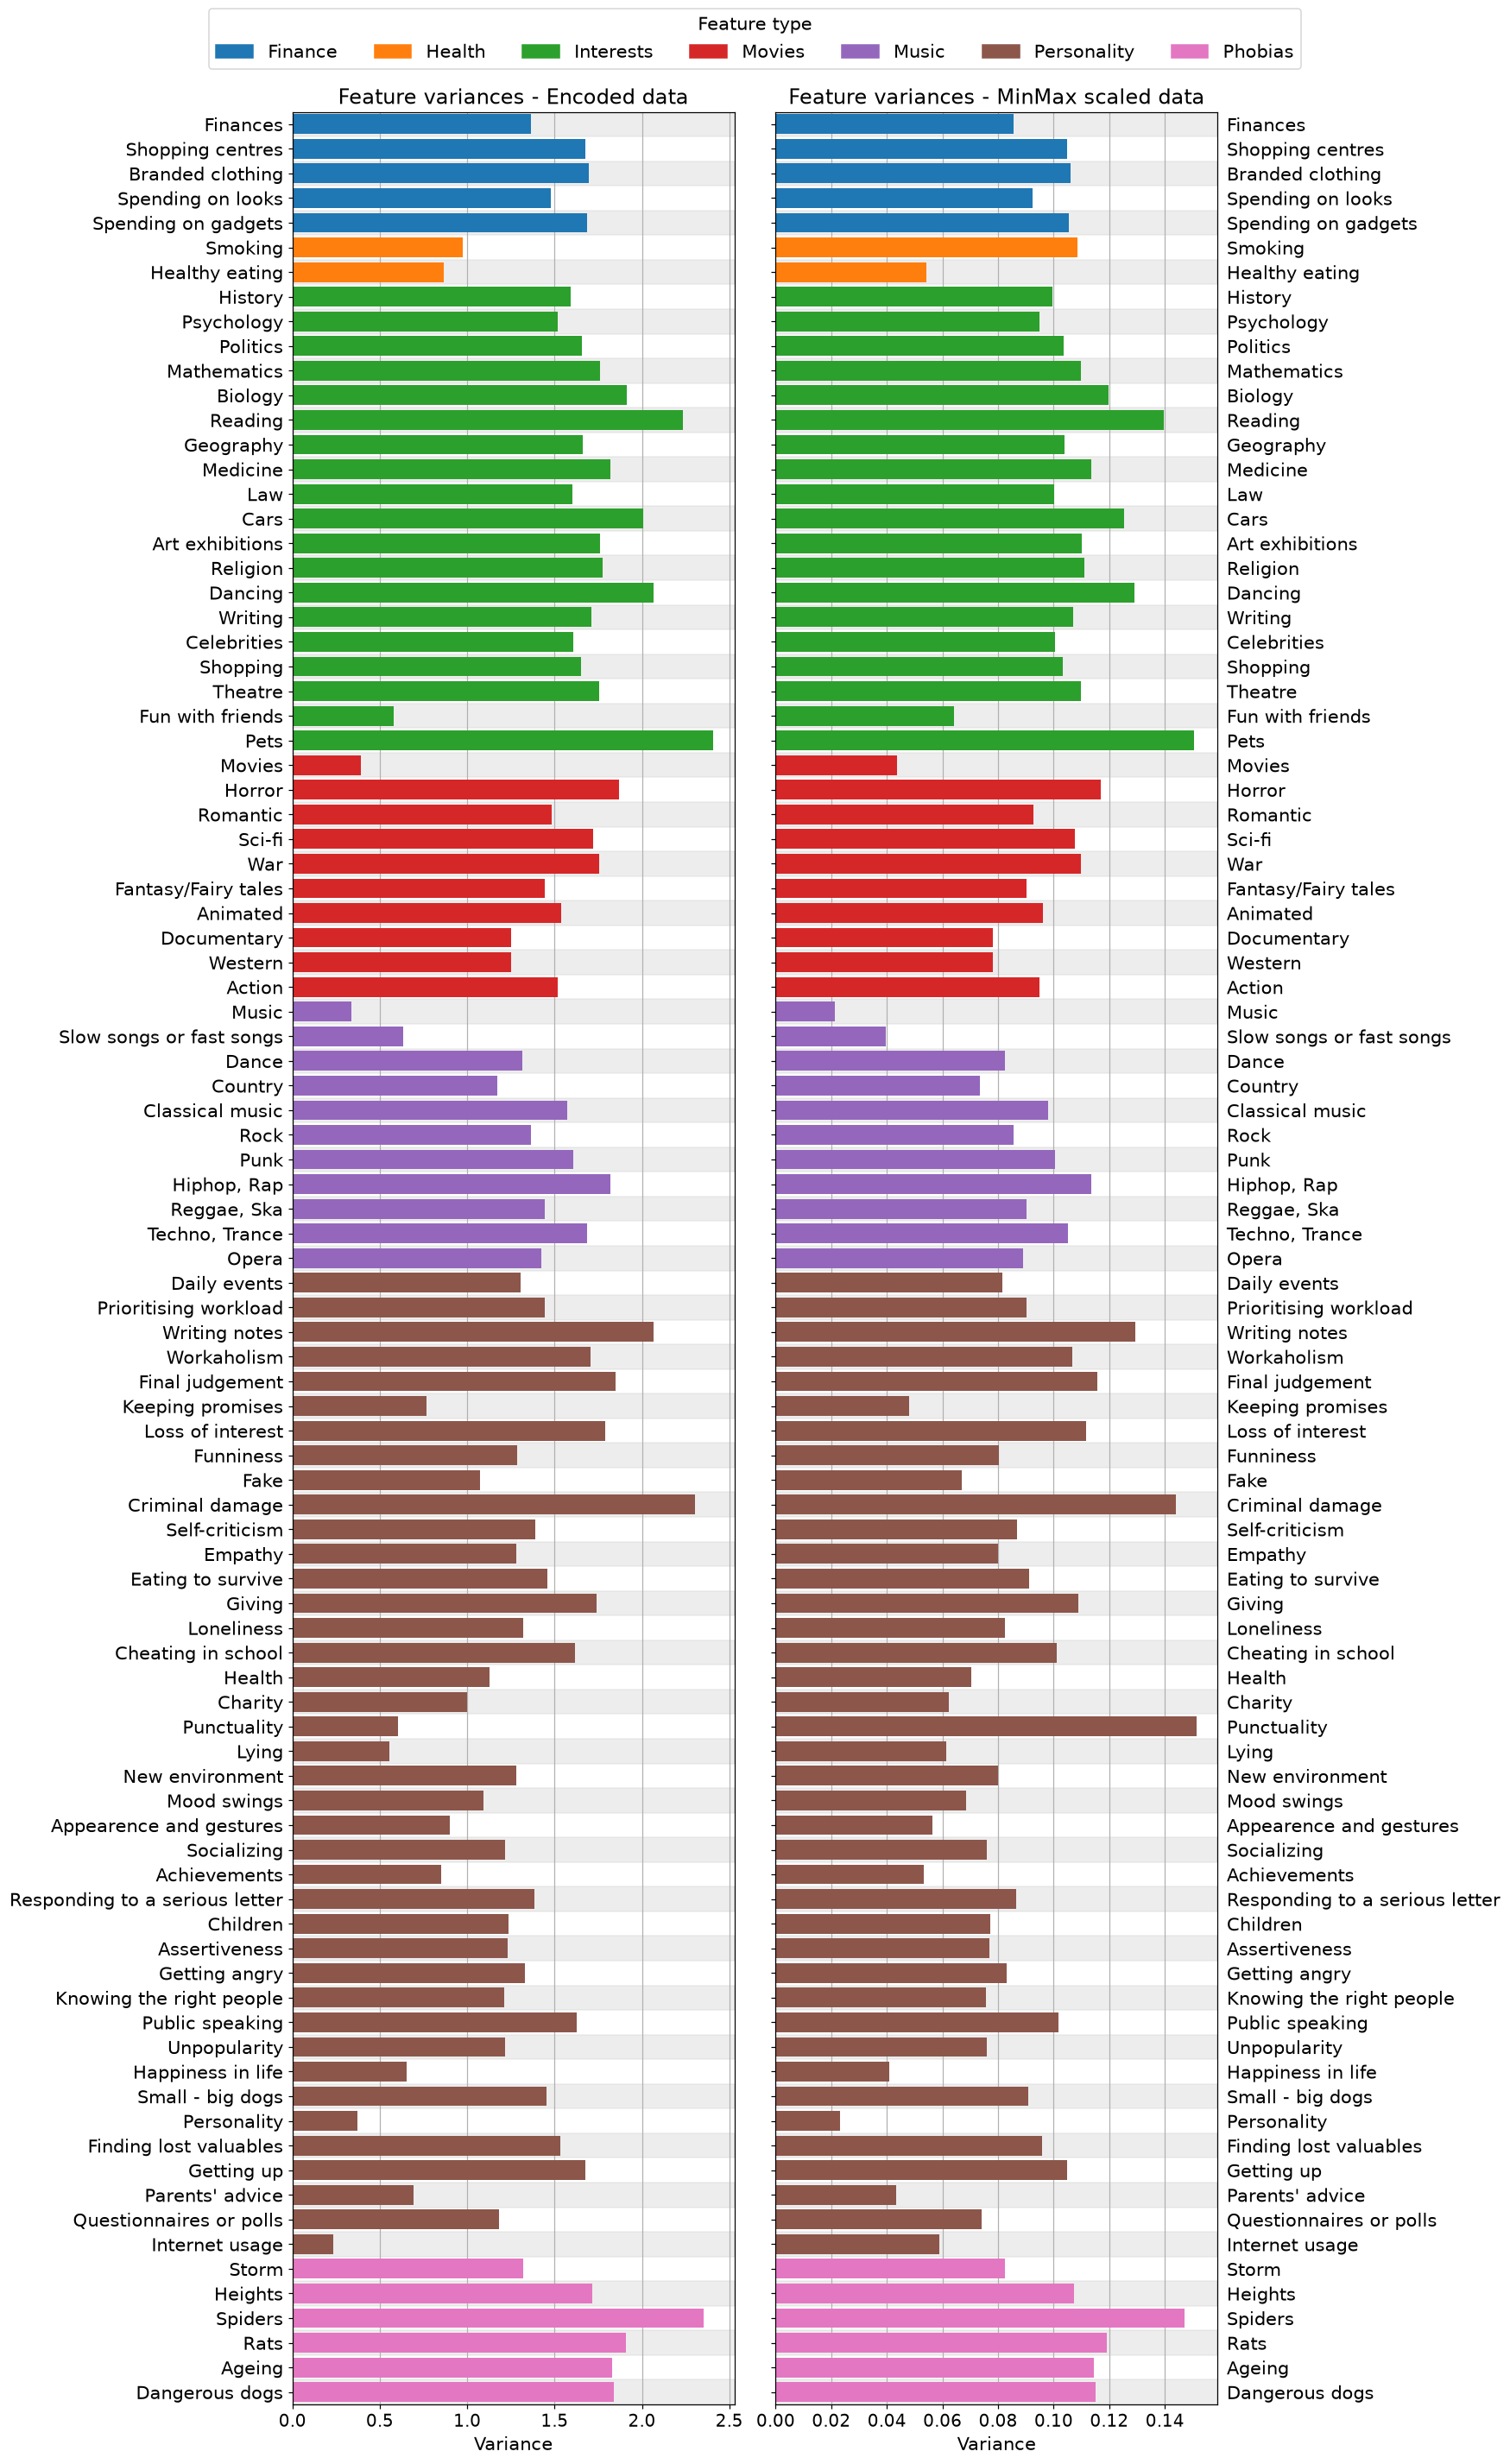

In [8]:
# Compute the variance of each feature
var_enc = responses_ft_enc.var()
var_pp = responses_ft_pp.var()

# Color each bar according to the feature type (Music, Movies, Phobias, ...)
types = list(features_by_type.keys())
type_colors = {tt: plt.get_cmap('tab10').colors[i] for i, tt in enumerate(types)}
feature_type = {ff: tt for tt in types for ff in features_by_type[tt]}
bar_colors = [type_colors[feature_type[ff]] for ff in var_enc.index]

# Horizontal barplots side by side: same feature on the same row in both plots
fig, axs = plt.subplots(1, 2, figsize=(16, 26), sharey=True, dpi=110)
y = np.arange(len(var_enc))

for ax, var, title in zip(axs, [var_enc, var_pp],
                          ['Feature variances - Encoded data',
                           'Feature variances - MinMax scaled data']):
    # Light gray band every other row, to guide the eye from left to right
    for i in range(0, len(y), 2):
        ax.axhspan(i - 0.5, i + 0.5, color='lightgray', alpha=0.4, zorder=0)

    ax.barh(y, var, color=bar_colors, zorder=2)
    ax.set_title(title, fontsize=16)
    ax.set_xlabel('Variance', fontsize=14)
    ax.tick_params(axis='x', labelsize=13)
    ax.grid(axis='x', zorder=1)

# Feature names on the left of the first plot and on the right of the second one
axs[0].set_yticks(y)
axs[0].set_yticklabels(var_enc.index, fontsize=14)
axs[1].tick_params(axis='y', labelright=True, labelsize=14)
axs[0].set_ylim(len(y) - 0.5, -0.5)  # first feature at the top, no empty space

# Legend with the feature types
handles = [plt.Rectangle((0, 0), 1, 1, color=type_colors[tt]) for tt in types]
fig.legend(handles, types, title='Feature type', loc='upper center',
           ncol=len(types), fontsize=14, title_fontsize=14)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

#### Comment the results obtained for the variances (max 150 words):
The two barplots have almost the same shape: since most features are 1–5 ratings (range 4), the MinMaxScaler divides their values by 4 and, therefore, their variances by $4^2 = 16$, keeping their proportions. The only visible changes concern the features with a smaller range, *Punctuality* and *Smoking*, which gain relative variance.

In both datasets the variances are quite heterogeneous. The lowest values belong to questions where almost all participants agree: e.g., 82% of them answered 5 to *Music* and 65% answered 3 to *Personality*. The highest values (*Pets*, *Spiders*, *Criminal damage*, *Reading*) belong to questions that divide people, with answers spread over the whole scale. By type, *Phobias* and *Interests* show the highest variances, while *Health* and some *Music* and *Personality* items are lower.

However, no feature clearly dominates the others, so we expect the total variance to be spread over many PCs.

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

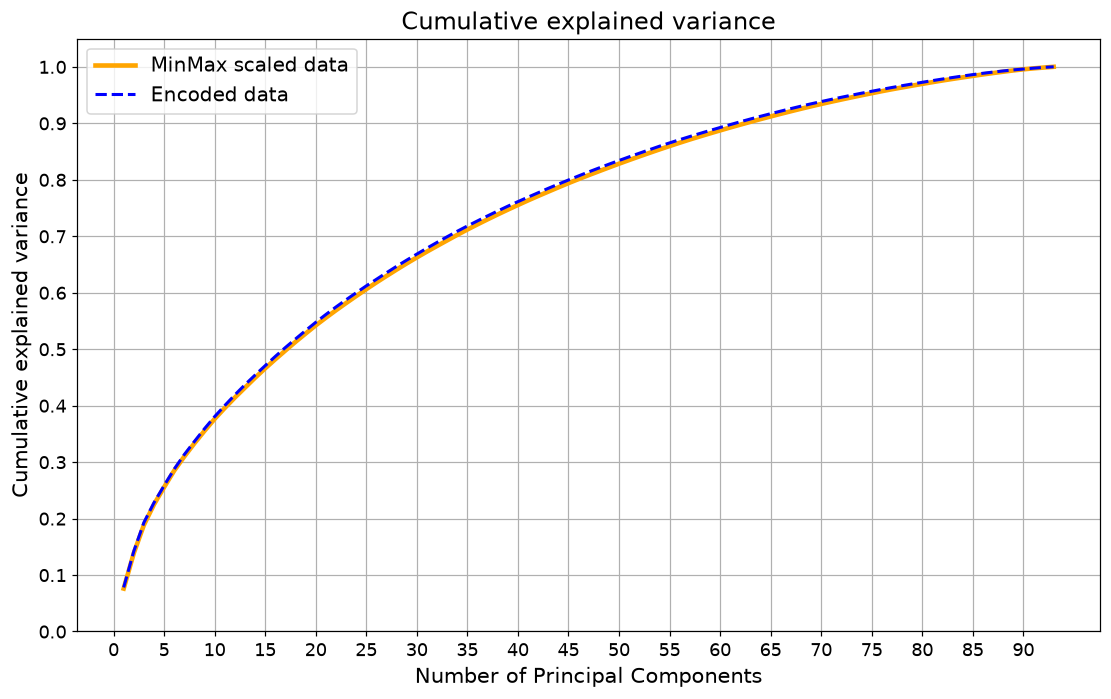

*** EXPLAINED VARIANCE RATIO OF THE FIRST 3 PCs


,Encoded,MinMax scaled
PC1,0.0780,0.0760
PC2,0.0640,0.0628
PC3,0.0509,0.0499


*** NUMBER OF PCs NEEDED TO REACH EACH THRESHOLD OF EXPLAINED VARIANCE


,Encoded,MinMax scaled
50%,17,18
80%,46,46
90%,62,63


In [9]:
# Initialize PCA objects
pca_enc = PCA()
pca_pp = PCA()

# Fit PCA on both datasets
pca_enc.fit(responses_ft_enc)
pca_pp.fit(responses_ft_pp)

# Compute cumulative explained variance
cumvar_enc = np.cumsum(pca_enc.explained_variance_ratio_)
cumvar_pp = np.cumsum(pca_pp.explained_variance_ratio_)

# Plot cumulative explained variance curves
plt.figure(figsize=(12, 7), dpi=110)

plt.plot(np.arange(1, len(cumvar_pp) + 1),
         cumvar_pp, label='MinMax scaled data',
         color='orange', linewidth=3)

plt.plot(np.arange(1, len(cumvar_enc) + 1),
         cumvar_enc, label='Encoded data',
         color='blue', linestyle='--',
         linewidth=2)

plt.title('Cumulative explained variance', fontsize=16)
plt.xlabel('Number of Principal Components', fontsize=14)
plt.ylabel('Cumulative explained variance', fontsize=14)
plt.xticks(np.arange(0, len(cumvar_enc) + 1, 5), fontsize=12)
plt.yticks(np.arange(0, 1.01, 0.1), fontsize=12)
plt.ylim([0, 1.05])
plt.legend(fontsize=13)
plt.grid()
plt.show()

# Values useful for the comment
print('*** EXPLAINED VARIANCE RATIO OF THE FIRST 3 PCs')
display(pd.DataFrame({'Encoded': pca_enc.explained_variance_ratio_[:3],
                      'MinMax scaled': pca_pp.explained_variance_ratio_[:3]},
                     index=['PC1', 'PC2', 'PC3']).round(4))

thresholds = [0.5, 0.8, 0.9]
print('*** NUMBER OF PCs NEEDED TO REACH EACH THRESHOLD OF EXPLAINED VARIANCE')
display(pd.DataFrame({
    'Encoded': [np.argmax(cumvar_enc >= t) + 1 for t in thresholds],
    'MinMax scaled': [np.argmax(cumvar_pp >= t) + 1 for t in thresholds]
}, index=[f'{int(t * 100)}%' for t in thresholds]))

#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):
The two curves are almost overlapping. Since all features take values on similar discrete scales (mostly 1–5 ratings), the MinMaxScaler divides almost all variances by the same factor (16), which does not change the fraction of variance explained by each PC. The small differences are due only to the few features with a different range (e.g., *Punctuality* and *Smoking*).

In both cases the curves grow slowly: PC1 explains less than 8% of the total variance, the first three PCs together about 19%, and 17–18 PCs are needed to reach 50% and 46 PCs (half of the 93) to reach 80%. This agrees with the feature variances: no feature dominates the others, and the answers to different questions are only weakly correlated, so the total variance is spread over many directions. Therefore, a strong dimensionality reduction will necessarily preserve only a limited part of the information.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

m' (PCs needed for 33% of the total variance): 8
m = min(m', 5) = 5


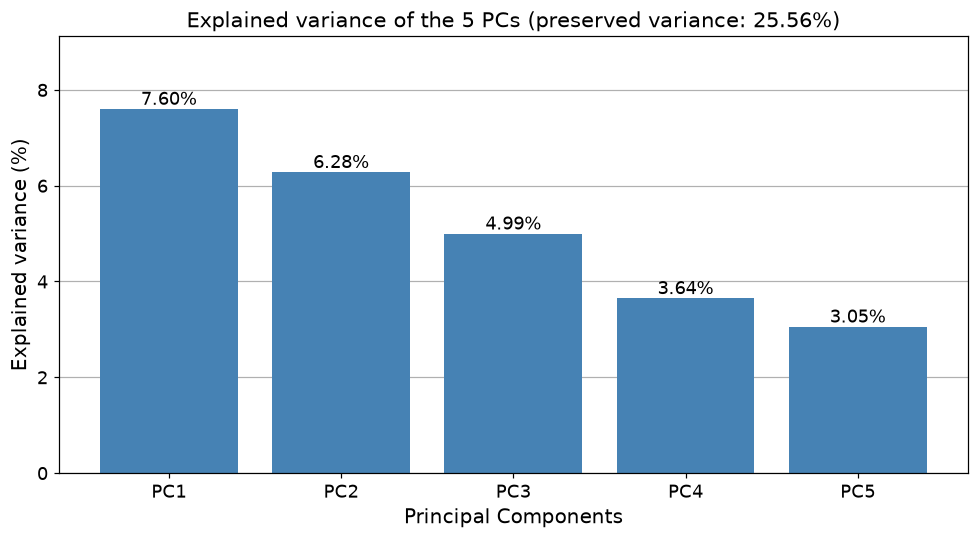

*** PRESERVED EXPLAINED VARIANCE BY THE 5 PCs: 25.56%


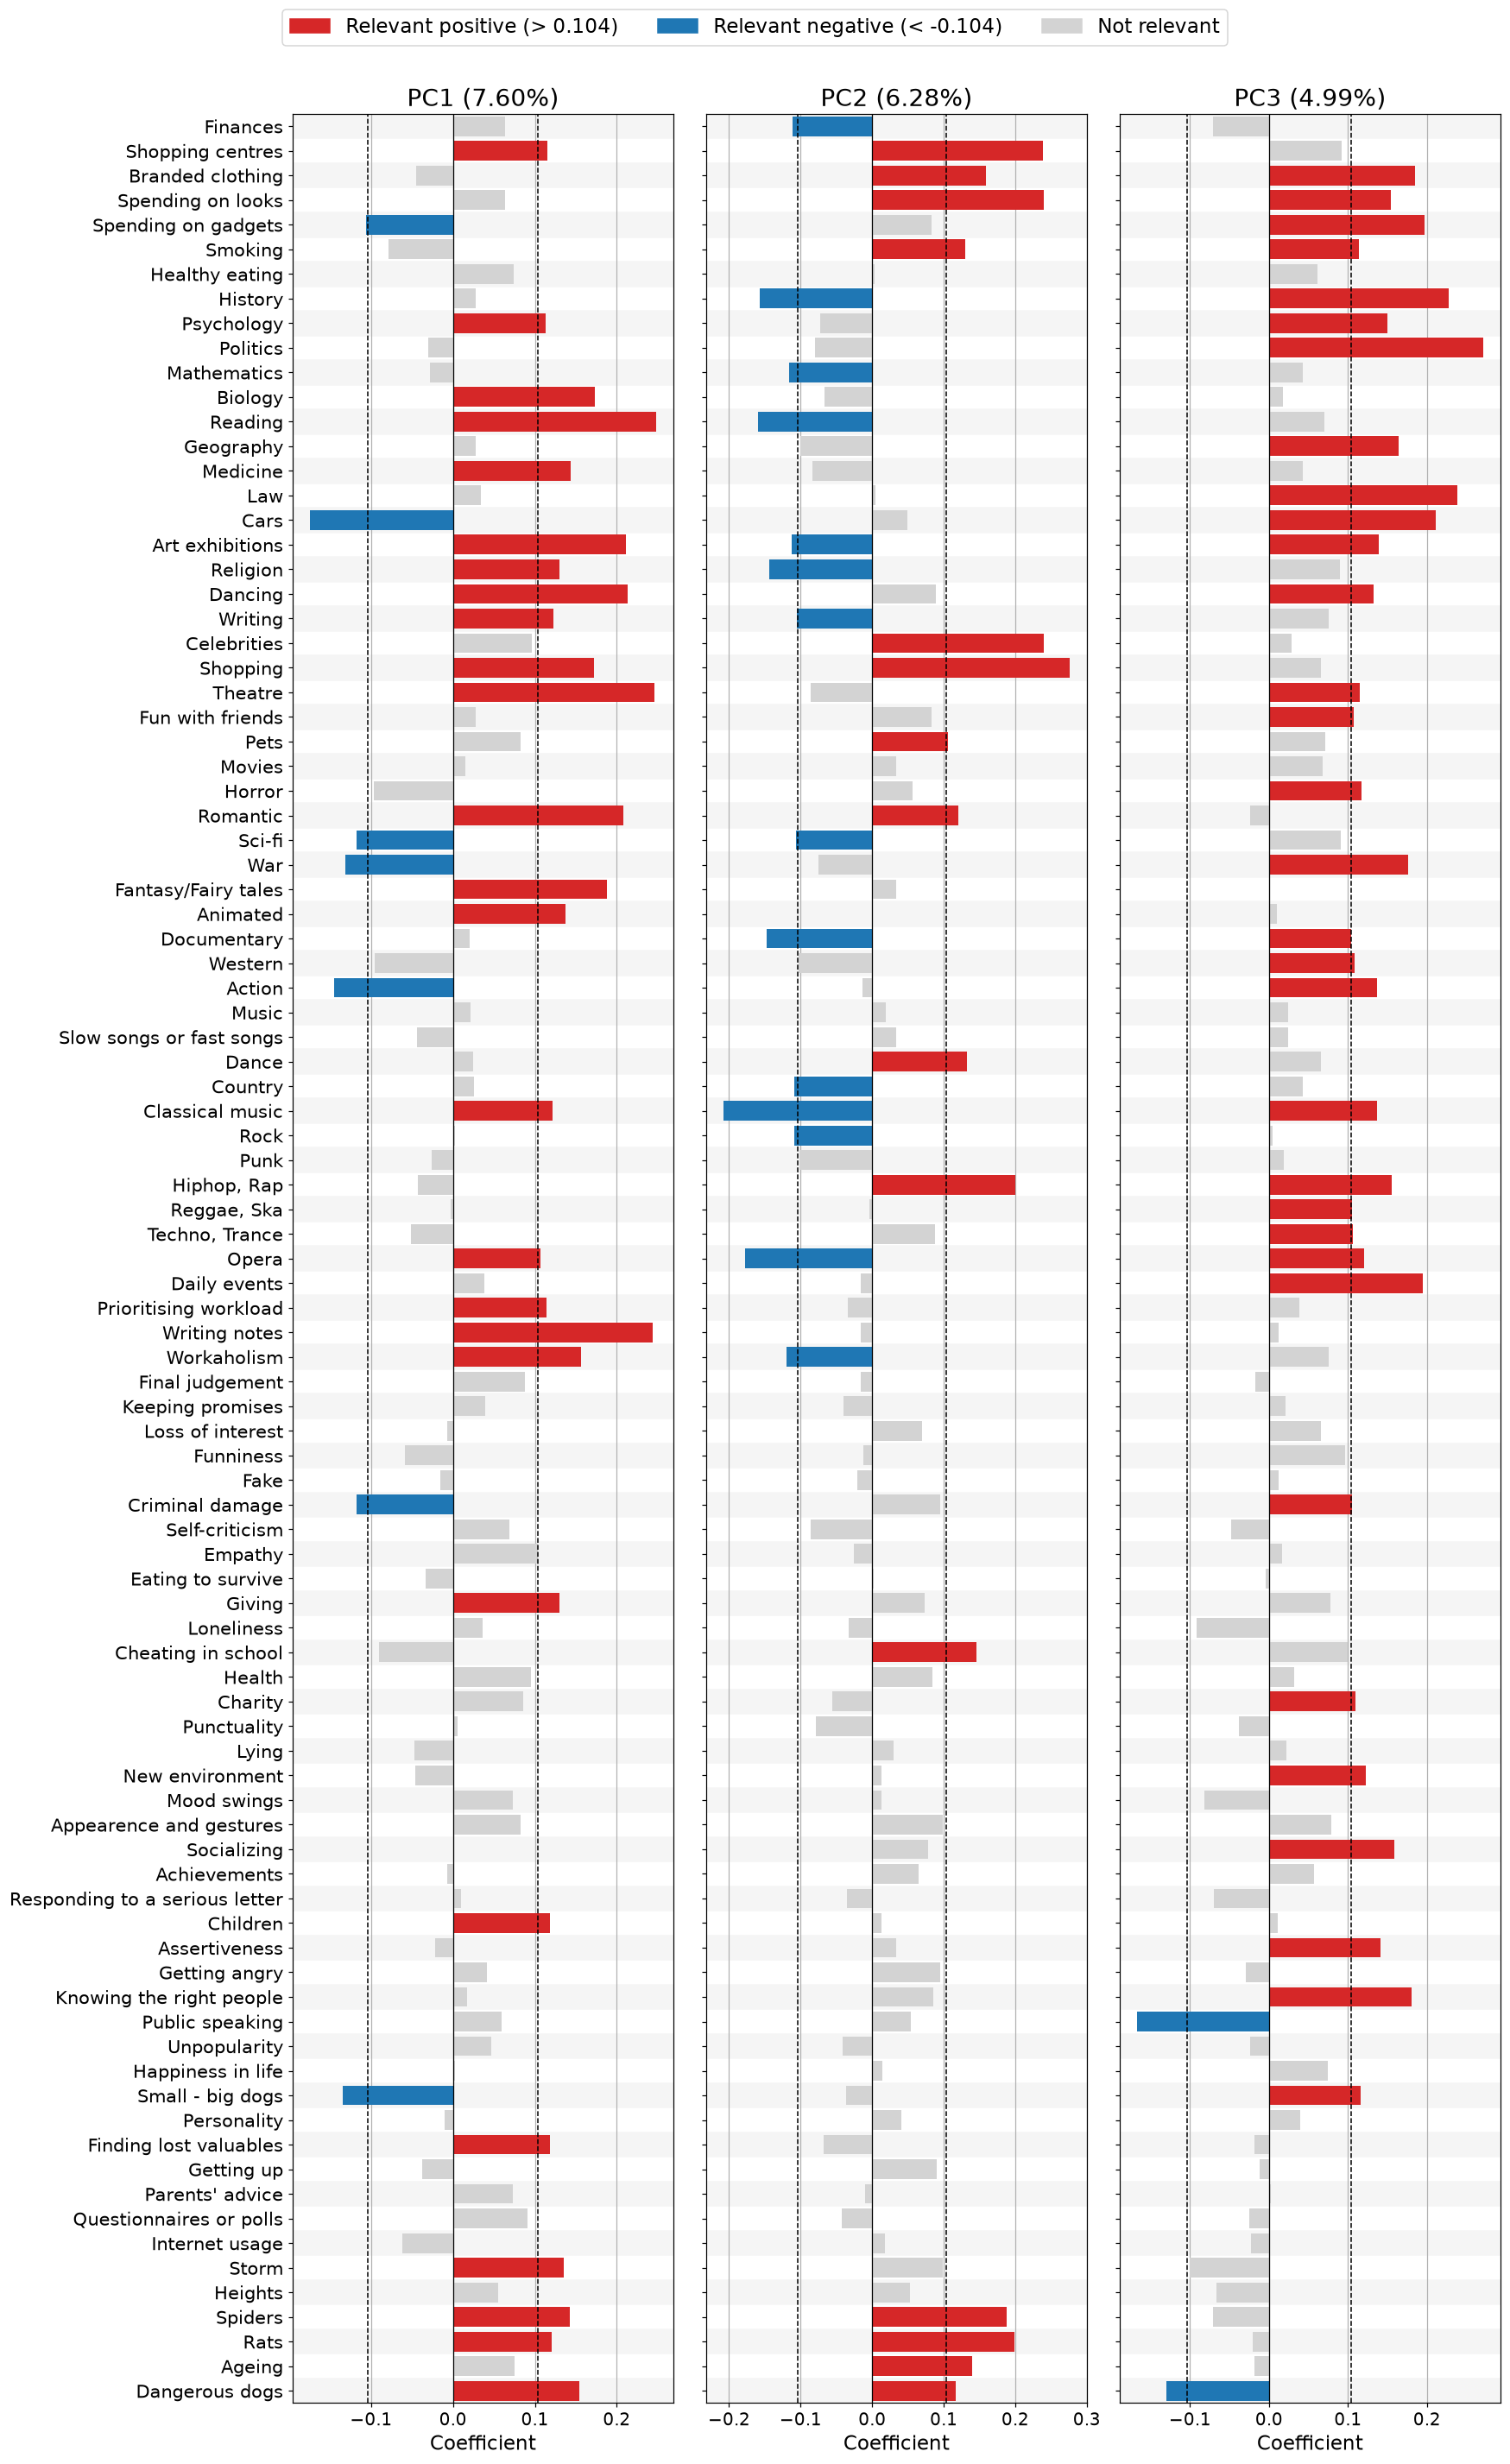

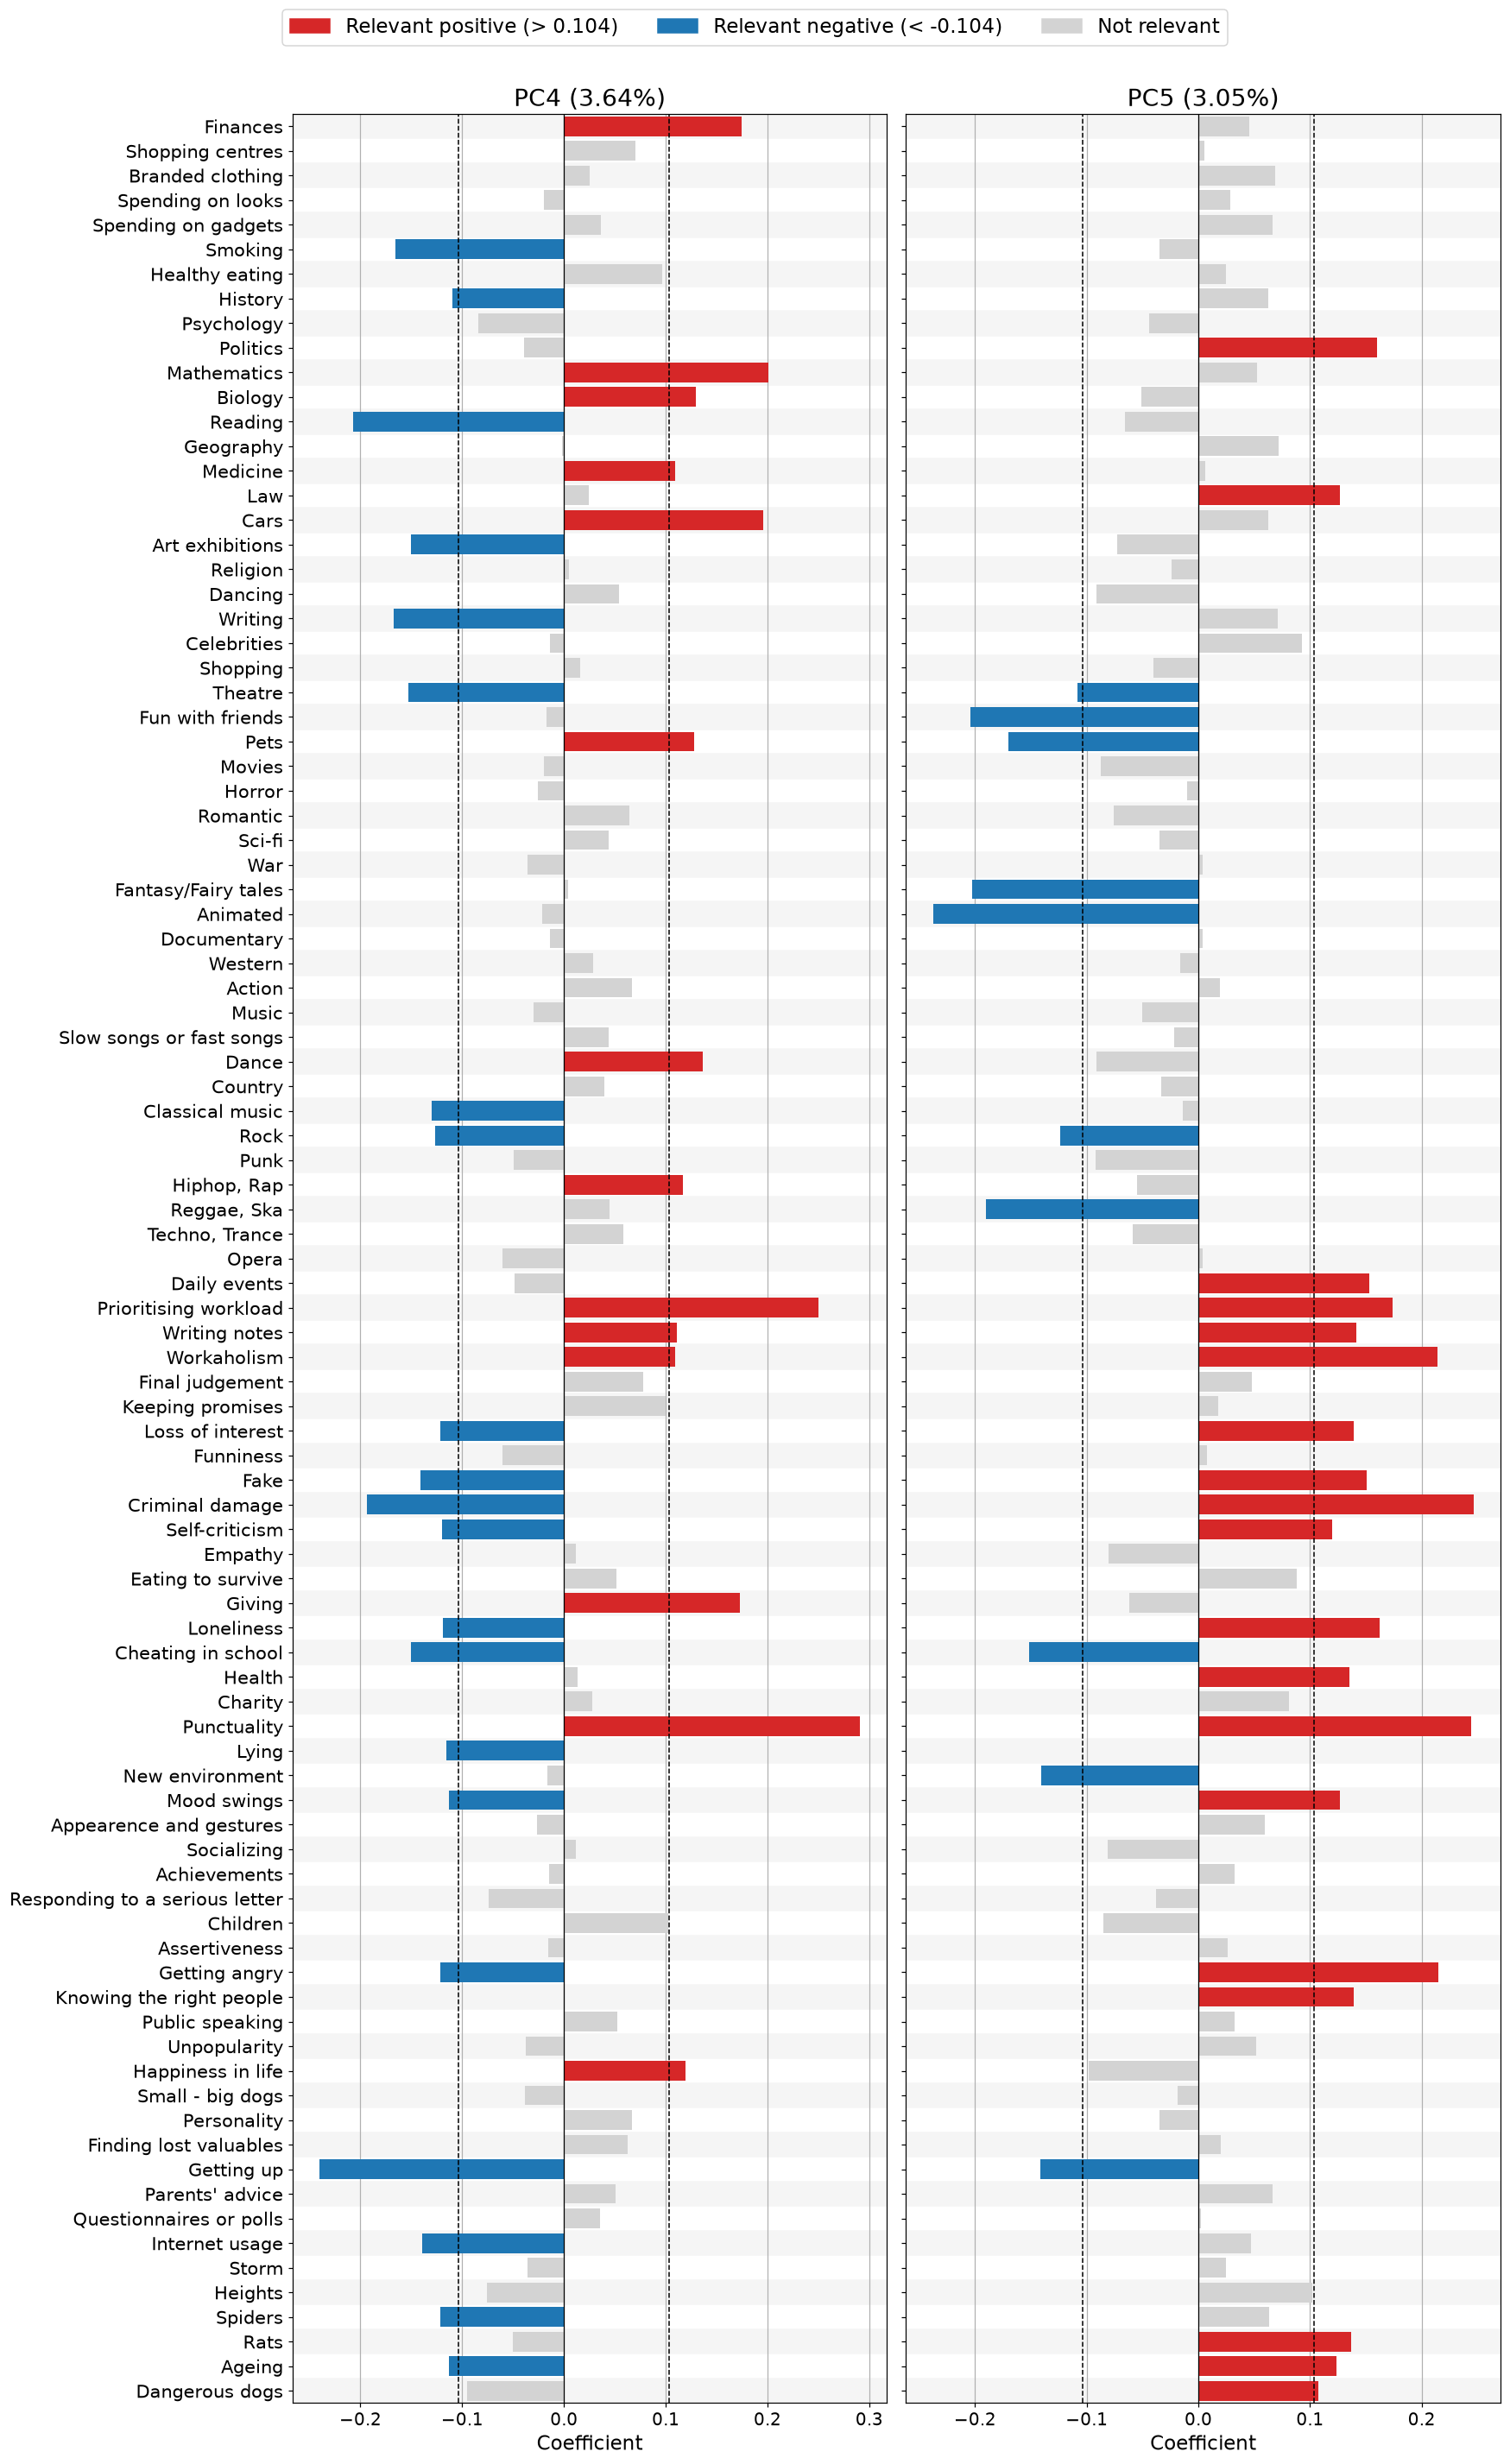

*** PC1: MOST RELEVANT FEATURES (|coefficient| > 0.104)


,Coefficient
Reading,0.248
Theatre,0.246
Writing notes,0.244
Dancing,0.213
Art exhibitions,0.211
Romantic,0.208
Fantasy/Fairy tales,0.188
Biology,0.173
Cars,-0.175
Action,-0.145


*** PC2: MOST RELEVANT FEATURES (|coefficient| > 0.104)


,Coefficient
Shopping,0.276
Spending on looks,0.240
Celebrities,0.239
Shopping centres,0.238
"Hiphop, Rap",0.200
Rats,0.199
Spiders,0.188
Branded clothing,0.159
Classical music,-0.208
Opera,-0.178


*** PC3: MOST RELEVANT FEATURES (|coefficient| > 0.104)


,Coefficient
Politics,0.271
Law,0.239
History,0.228
Cars,0.211
Spending on gadgets,0.197
Daily events,0.195
Branded clothing,0.185
Knowing the right people,0.181
Public speaking,-0.167
Dangerous dogs,-0.130


*** PC4: MOST RELEVANT FEATURES (|coefficient| > 0.104)


,Coefficient
Punctuality,0.291
Prioritising workload,0.250
Mathematics,0.201
Cars,0.196
Finances,0.175
Giving,0.173
Dance,0.136
Biology,0.129
Getting up,-0.240
Reading,-0.207


*** PC5: MOST RELEVANT FEATURES (|coefficient| > 0.104)


,Coefficient
Criminal damage,0.246
Punctuality,0.244
Getting angry,0.215
Workaholism,0.214
Prioritising workload,0.174
Loneliness,0.162
Politics,0.160
Daily events,0.153
Animated,-0.238
Fun with friends,-0.204


In [10]:
# Choice of m
cumvar_pp = np.cumsum(pca_pp.explained_variance_ratio_)

# m' = smallest number of PCs that explains at least 33% of the total variance
m_prime = np.argmax(cumvar_pp >= 0.33) + 1
m = min(m_prime, 5)

print(f"m' (PCs needed for 33% of the total variance): {m_prime}")
print(f'm = min(m\', 5) = {m}')

# New PCA with m components
pca_m = PCA(n_components=m)
pca_m.fit(responses_ft_pp)

pc_labels = [f'PC{i}' for i in range(1, m + 1)]
expl_var_perc = pca_m.explained_variance_ratio_ * 100
preserved_var = expl_var_perc.sum()

# Explained variance (%) of each PC
plt.figure(figsize=(9, 5), dpi=110)
bars = plt.bar(pc_labels, expl_var_perc, color='steelblue', zorder=2)
plt.bar_label(bars, fmt='%.2f%%', fontsize=12)  # write the explained variance (%) on top of each bar

plt.title(f'Explained variance of the {m} PCs (preserved variance: {preserved_var:.2f}%)',
          fontsize=14)
plt.xlabel('Principal Components', fontsize=13)
plt.ylabel('Explained variance (%)', fontsize=13)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim([0, expl_var_perc.max() * 1.2])
plt.grid(axis='y', zorder=1) # zorder sets the drawing order: bands (0) behind, grid (1) in the middle, bars (2) in front
plt.tight_layout()
plt.show()

print(f'*** PRESERVED EXPLAINED VARIANCE BY THE {m} PCs: {preserved_var:.2f}%')

# BARPLOTS OF THE m PCs
# Threshold for the relevant coefficients: if all the n features contributed equally,
# each coefficient of the (unit norm) PC would be equal to 1/sqrt(n)
n_feat = pca_m.n_features_in_
eps = np.sqrt(1 / n_feat)
features_names = responses_ft_pp.columns
y = np.arange(n_feat)

# PCs are plotted in groups of at most 3 per figure, to keep bars and labels readable
per_fig = 3
handles = [plt.Rectangle((0, 0), 1, 1, color=cc) for cc in ['tab:red', 'tab:blue', 'lightgray']]
legend_labels = [f'Relevant positive (> {eps:.3f})', f'Relevant negative (< -{eps:.3f})', 'Not relevant']

for start in range(0, m, per_fig):
    pcs_group = list(range(start, min(start + per_fig, m)))

    fig, axs = plt.subplots(1, len(pcs_group), figsize=(16, 26), sharey=True, dpi=110,
                            squeeze=False)
    axs = axs[0]

    for ax, i in zip(axs, pcs_group):
        coeffs = pca_m.components_[i, :]

        # Red = relevant positive, blue = relevant negative, gray = not relevant
        colors = ['tab:red' if c > eps else 'tab:blue' if c < -eps else 'lightgray'
                  for c in coeffs]

        for j in range(0, n_feat, 2):
            # axhspan draws a light gray horizontal band every other row, to guide the eye from left to right
            ax.axhspan(j - 0.5, j + 0.5, color='whitesmoke', zorder=0)

        ax.barh(y, coeffs, color=colors, zorder=2)
        ax.axvline(eps, color='black', linestyle='--', linewidth=1)
        ax.axvline(-eps, color='black', linestyle='--', linewidth=1)
        ax.axvline(0, color='black', linewidth=0.8)

        ax.set_title(f'{pc_labels[i]} ({expl_var_perc[i]:.2f}%)', fontsize=18)
        ax.set_xlabel('Coefficient', fontsize=15)
        ax.tick_params(axis='x', labelsize=13)
        ax.grid(axis='x', zorder=1)   

    axs[0].set_yticks(y)
    axs[0].set_yticklabels(features_names, fontsize=14)
    axs[0].set_ylim(n_feat - 0.5, -0.5)  # first feature at the top, no empty space

    # Legend for the colors
    fig.legend(handles, legend_labels, loc='upper center', ncol=3, fontsize=15)

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

# MOST RELEVANT FEATURES OF EACH PC
for i in range(m):
    coeffs = pd.Series(pca_m.components_[i, :], index=features_names)
    positive = coeffs[coeffs > eps].sort_values(ascending=False).head(8)  # 8 largest positive
    negative = coeffs[coeffs < -eps].sort_values().head(8)                # 8 largest negative

    print(f'*** {pc_labels[i]}: MOST RELEVANT FEATURES (|coefficient| > {eps:.3f})')
    display(pd.concat([positive, negative]).round(3).to_frame('Coefficient'))

#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

**PC1 – "Artistic vs Action-oriented"**

PC1 has high positive coefficients for cultural and artistic interests (*Reading*, *Theatre*, *Art exhibitions*, *Dancing*), romantic and fantasy movies, and *Writing notes*. Several phobias (*Spiders*, *Rats*, *Storm*, *Dangerous dogs*) are also positive, so these people also tend to be more sensitive and fearful. On the negative side, we find *Cars*, *Action*, *War*, *Sci-fi*, *Spending on gadgets*, the preference for big dangerous dogs (*Small - big dogs*) and having damaged things when angry (*Criminal damage*). Therefore, low PC1 values describe people attracted by action and technology, with more impulsive behaviours.

**PC2 – "Consumerist vs Intellectual"**

PC2 has high positive coefficients for shopping and appearance (*Shopping*, *Shopping centres*, *Spending on looks*, *Branded clothing*), for *Celebrities* and for popular music such as *Hiphop, Rap*. Some phobias (*Rats*, *Spiders*) are also positive. On the negative side, we find classical culture and study: *Classical music*, *Opera*, *Reading*, *History*, *Documentary*, *Religion*, *Mathematics* and *Workaholism*. Therefore, high PC2 values describe consumerist people, interested in image and pop culture, while low values describe intellectual people, interested in traditional culture, knowledge and studying.

**PC3 – "Socially Ambitious"**

PC3 has almost only positive relevant coefficients, so we gave it a single-sided name. The highest ones concern public affairs (*Politics*, *Law*, *History*, *Daily events*), status and image (*Cars*, *Spending on gadgets*, *Branded clothing*) and social relations (*Knowing the right people*, *Socializing*, *Assertiveness*). The only negative coefficients are *Public speaking* (needing to be well prepared before speaking in public) and the fear of *Dangerous dogs*. Therefore, high PC3 values describe self-confident people, interested in current events, social status and useful relationships, while low values describe people less involved in these aspects.

**PC4 – "Disciplined vs Irregular"**

PC4 has high positive coefficients for organized and responsible habits: being early (*Punctuality*), doing tasks as soon as possible (*Prioritising workload*) and saving money (*Finances*), together with rational interests such as *Mathematics*, *Cars* and *Biology*. On the negative side, we find difficulty in getting up in the morning (*Getting up*), *Smoking*, *Cheating in school* and having damaged things when angry (*Criminal damage*), together with artistic interests (*Reading*, *Writing*, *Theatre*, *Art exhibitions*). Therefore, high PC4 values describe disciplined and practical people, while low values describe people with a more irregular lifestyle and artistic interests.

**PC5 – "Tense vs Carefree"**

PC5 has high positive coefficients for a serious and tense attitude: being early (*Punctuality*), working even in spare time (*Workaholism*, *Prioritising workload*), attention to *Politics* and *Daily events*, but also getting angry easily (*Getting angry*, *Criminal damage*) and feeling lonely (*Loneliness*). On the negative side, we find light-hearted interests (*Animated*, *Fantasy/Fairy tales*, *Reggae, Ska*, *Pets*), having fun with friends (*Fun with friends*) and adapting quickly to new environments (*New environment*). Therefore, high PC5 values describe dutiful but stressed and lonely people, while low values describe carefree, playful and sociable people.

#### Write the code for visualizing the score graph (with PC names on the axis):

*** SHAPE OF responses_ft_pca: (506, 5)


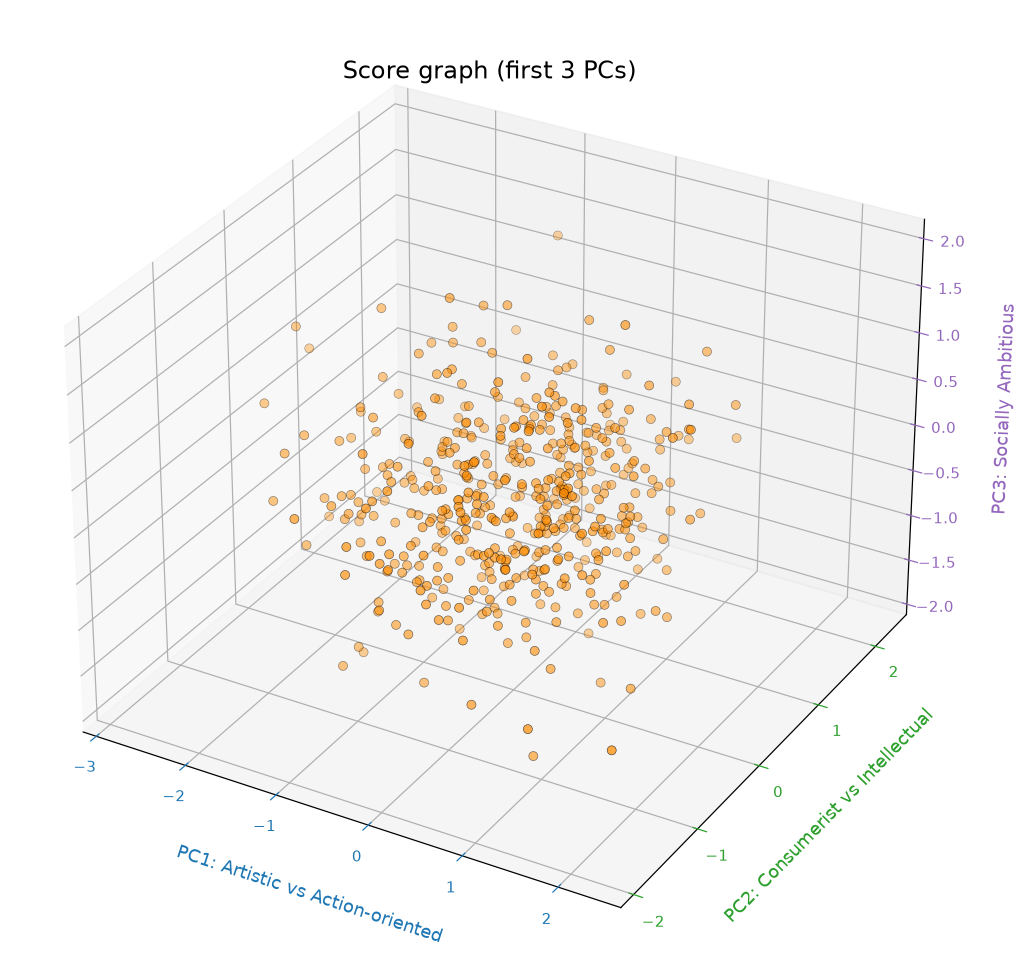

In [11]:
# Transform the data into their m-dimensional representation via PCA
responses_ft_pca = pca_m.transform(responses_ft_pp)
print(f'*** SHAPE OF responses_ft_pca: {responses_ft_pca.shape}')

# Names assigned to the m Principal Components
pc_names = ['Artistic vs Action-oriented',
            'Consumerist vs Intellectual',
            'Socially Ambitious',
            'Disciplined vs Irregular',
            'Tense vs Carefree']

# One color for each of the 3 axes
axis_colors = ['tab:blue', 'tab:green', 'tab:purple']

# Score graph with respect to the first 3 PCs (m > 3)
fig = plt.figure(figsize=(11, 9), dpi=110)
ax = fig.add_subplot(111, projection='3d')

ax.scatter(responses_ft_pca[:, 0],
           responses_ft_pca[:, 1],
           responses_ft_pca[:, 2],
           color='darkorange', edgecolor='black',
           linewidth=0.4, s=35, alpha=0.85)

# Axis labels with PC names
ax.set_xlabel(f'PC1: {pc_names[0]}',
              fontsize=12, labelpad=15, color=axis_colors[0])

ax.set_ylabel(f'PC2: {pc_names[1]}',
              fontsize=12, labelpad=15, color=axis_colors[1])

ax.set_zlabel(f'PC3: {pc_names[2]}',
              fontsize=12, labelpad=15, color=axis_colors[2])

# Tick labels with the same color of their axis
ax.tick_params(axis='x', colors=axis_colors[0], labelsize=10)
ax.tick_params(axis='y', colors=axis_colors[1], labelsize=10)
ax.tick_params(axis='z', colors=axis_colors[2], labelsize=10)

ax.set_title('Score graph (first 3 PCs)', fontsize=16, y=1.0)

plt.tight_layout()
plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

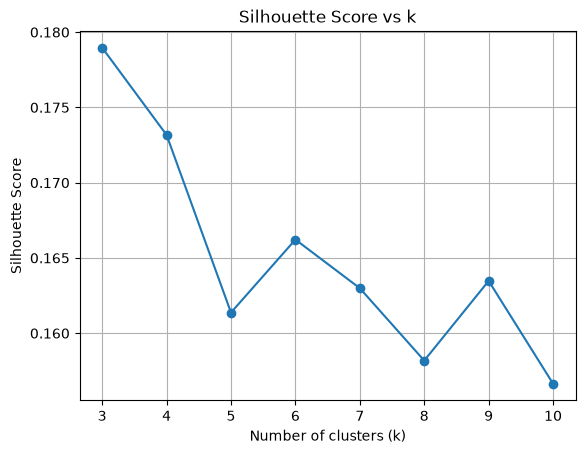

Best k: 3
Silhouette Score: 0.1790


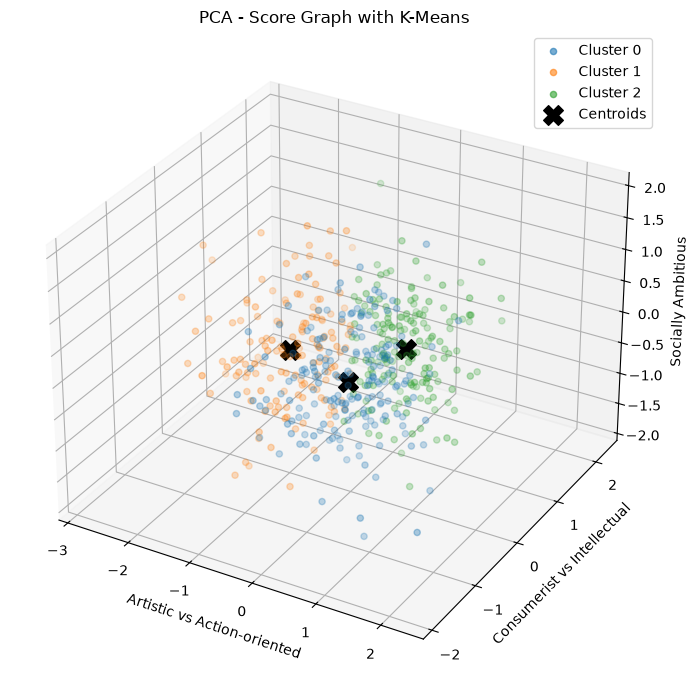

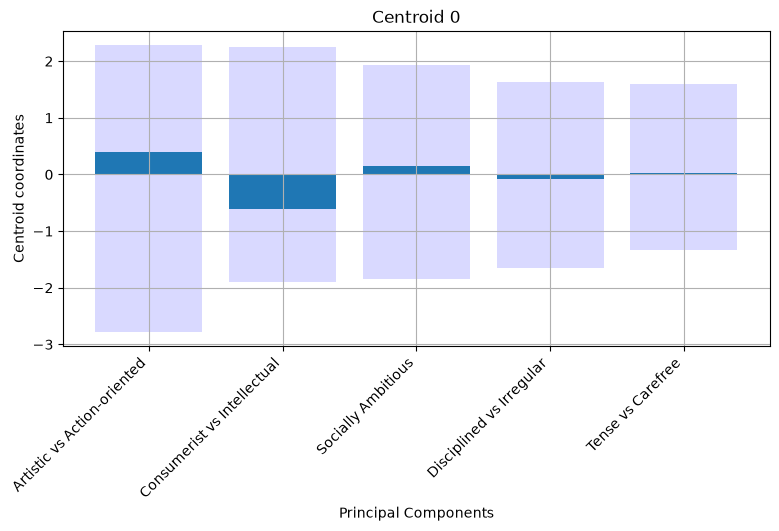

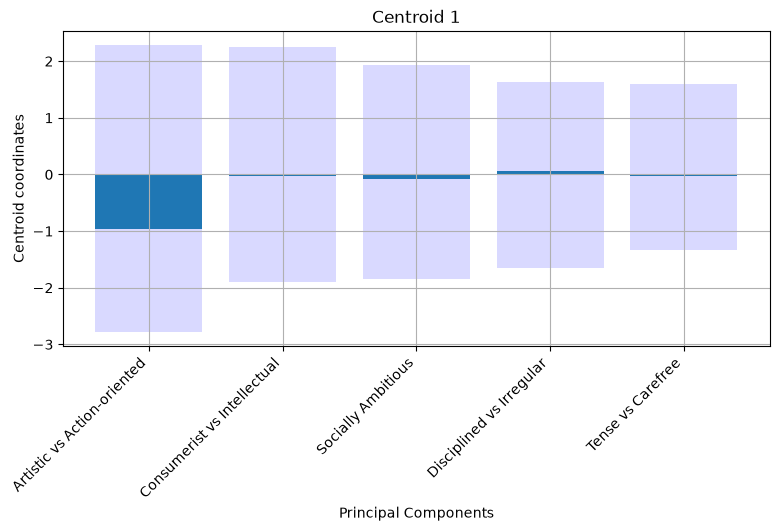

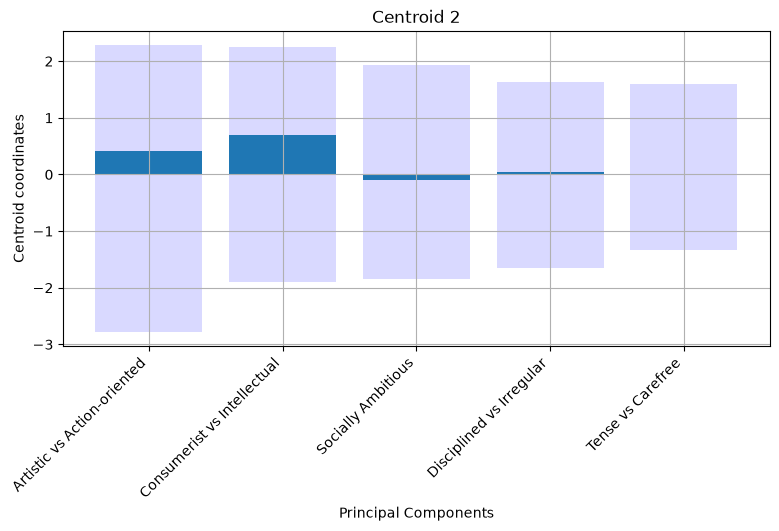

In [12]:
# 1. Find the best k using the silhouette score
k_values = np.arange(3, 11)
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=random_seed, n_init=10)
    km.fit(responses_ft_pca)

    score = silhouette_score(responses_ft_pca, km.labels_)
    silhouette_scores.append(score)

# Plot silhouette scores
plt.figure()
plt.plot(k_values, silhouette_scores, marker='o')
plt.xticks(k_values)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k')
plt.grid()
plt.show()

# Select the best k
best_k = k_values[np.argmax(silhouette_scores)]
print(f'Best k: {best_k}')

# Fit K-Means with the best k
km_best = KMeans(n_clusters=best_k, random_state=random_seed, n_init=10)
km_best.fit(responses_ft_pca)

print(f'Silhouette Score: {silhouette_score(responses_ft_pca, km_best.labels_):.4f}')


# 2. Score graph with clusters and centroids
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

colors = plt.get_cmap('tab10').colors

for i in range(best_k):
    mask = km_best.labels_ == i

    ax.scatter(
        responses_ft_pca[mask, 0],
        responses_ft_pca[mask, 1],
        responses_ft_pca[mask, 2],
        color=colors[i],
        label=f'Cluster {i}',
        alpha=0.6
    )

# Plot centroids
ax.scatter(
    km_best.cluster_centers_[:, 0],
    km_best.cluster_centers_[:, 1],
    km_best.cluster_centers_[:, 2],
    c='black',
    marker='X',
    s=200,
    label='Centroids',
    depthshade=False
)

ax.set_title('PCA - Score Graph with K-Means')
ax.set_xlabel(pc_names[0])
ax.set_ylabel(pc_names[1])
ax.set_zlabel(pc_names[2])

ax.legend()
plt.tight_layout()
plt.show()


# 3. Plot centroid coordinates as barplots
maxs = responses_ft_pca.max(axis=0)
mins = responses_ft_pca.min(axis=0)

for i in range(best_k):
    plt.figure(figsize=(8, 5))

    # Show the range of each PC
    plt.bar(np.arange(m), maxs, color='blue', alpha=0.15)
    plt.bar(np.arange(m), mins, color='blue', alpha=0.15)

    # Centroid coordinates
    plt.bar(np.arange(m), km_best.cluster_centers_[i, :])

    plt.xticks(np.arange(m), pc_names, rotation=45, ha='right')
    plt.tight_layout()
    plt.xlabel('Principal Components')
    plt.ylabel('Centroid coordinates')
    plt.title(f'Centroid {i}')
    plt.grid()
    plt.show()


#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):


**Centroid 0 – "Artistic Intellectuals"**

The first centroid is mainly characterized by positive values of PC1 (*Artistic vs Action-oriented*) and negative values of PC2 (*Consumerist vs Intellectual*). Therefore, this cluster represents people who tend to be interested in art, traditional culture, reading and knowledge rather than shopping and physical appearance. The slightly positive value of PC3 (*Socially Ambitious*) also suggests a moderate tendency towards social ambition. PC4 and PC5 are close to zero and do not particularly characterize this cluster.

**Centroid 1 – "Action-Oriented People"**

The second centroid is mainly characterized by a strongly negative value of PC1 (*Artistic vs Action-oriented*). Therefore, this cluster represents people who tend to prefer dynamic interests such as cars, action movies, science fiction and technology over artistic and cultural activities. The remaining PCs have values close to zero, suggesting that consumerism, social ambition, discipline and emotional attitude are not distinctive characteristics of this cluster.

**Centroid 2 – "Artistic Consumers"**

The third centroid is characterized by positive values of both PC1 (*Artistic vs Action-oriented*) and PC2 (*Consumerist vs Intellectual*). Therefore, this cluster represents people who combine artistic and creative interests with an interest in shopping, physical appearance, celebrities and popular culture. The remaining PCs have values close to zero and do not particularly characterize this cluster. Unlike the first cluster, these people tend to be more consumer-oriented while sharing similar artistic interests.


## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

...


#### Write the code for the visualizations cited in item 2 above:

Distribution of Gender:


,All,Cluster 0,Cluster 1,Cluster 2
female,0.602767,0.670213,0.195946,0.882353
male,0.397233,0.329787,0.804054,0.117647


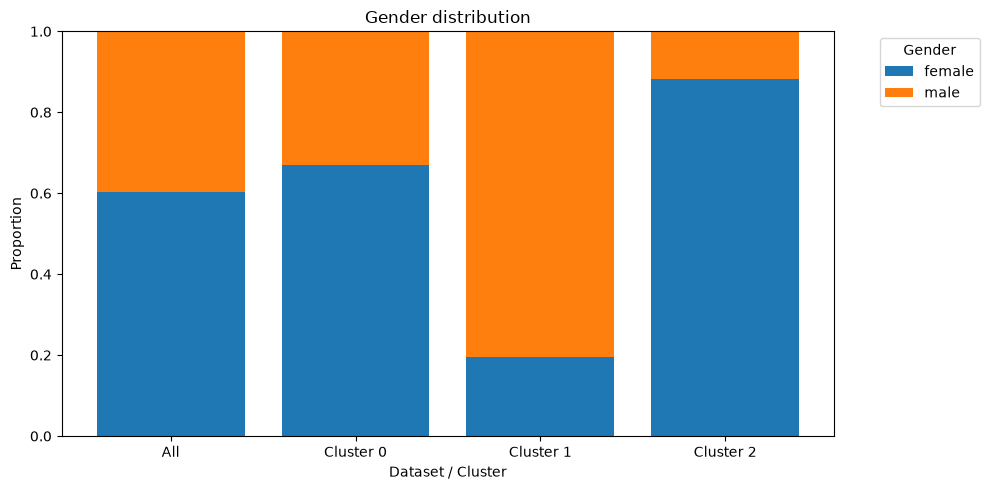

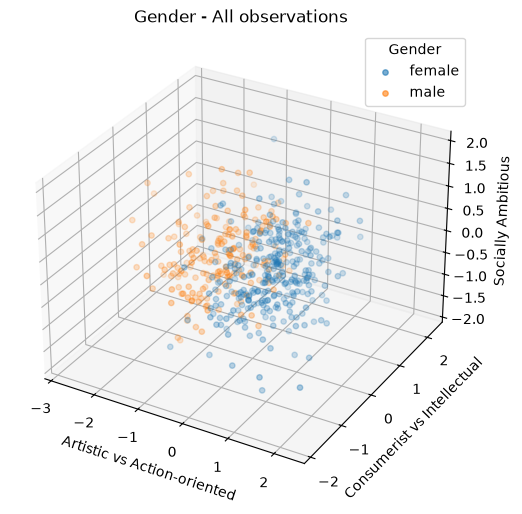

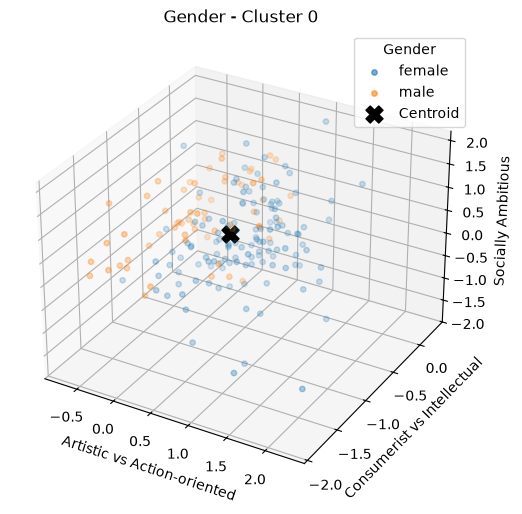

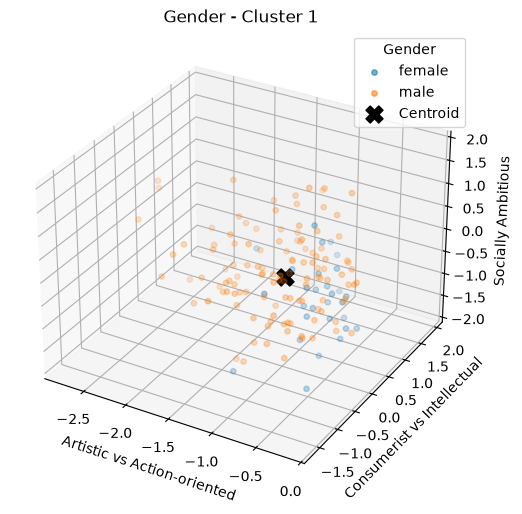

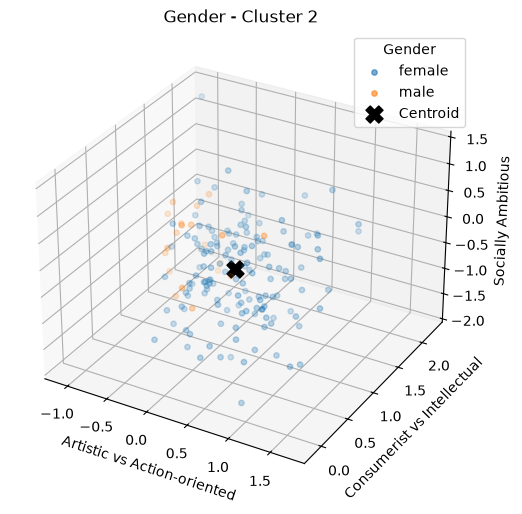

Distribution of Education:


,All,Cluster 0,Cluster 1,Cluster 2
college/bachelor degree,0.197628,0.223404,0.162162,0.2
currently a primary school pupil,0.003953,0.0,0.0,0.011765
doctorate degree,0.003953,0.005319,0.0,0.005882
masters degree,0.073123,0.095745,0.040541,0.076471
primary school,0.077075,0.085106,0.101351,0.047059
secondary school,0.644269,0.590426,0.695946,0.658824


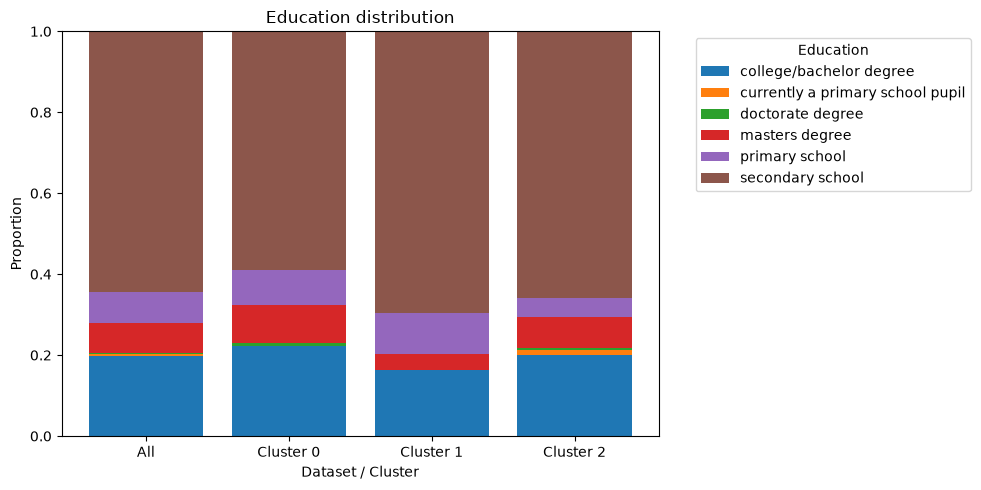

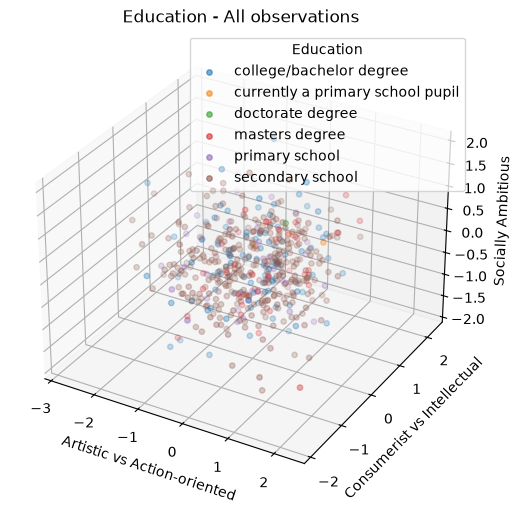

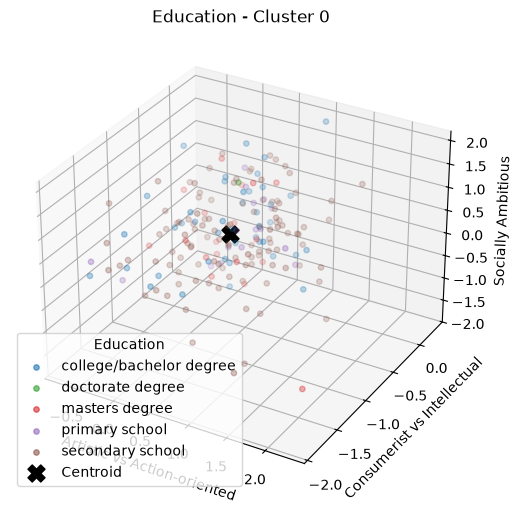

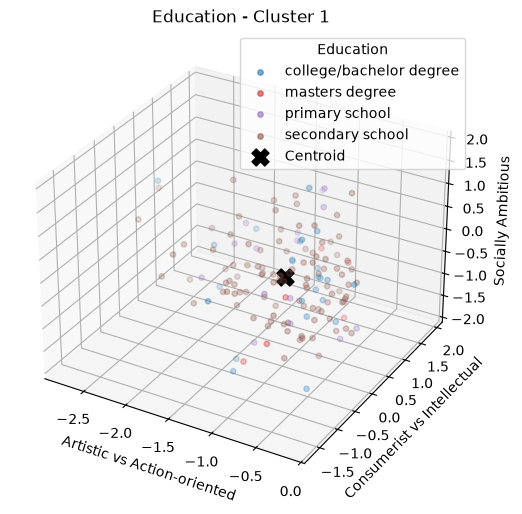

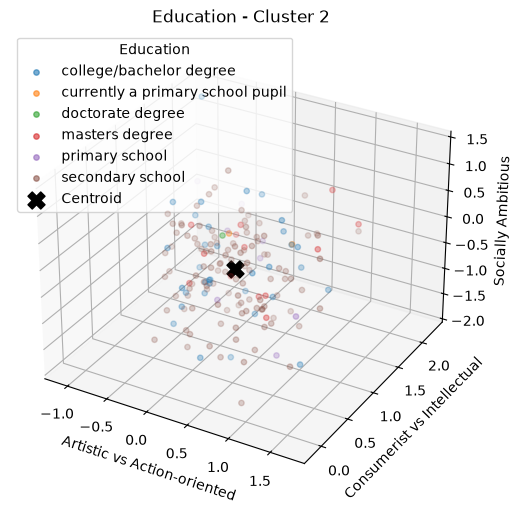

Distribution of Home Town Type:


,All,Cluster 0,Cluster 1,Cluster 2
city,0.715415,0.68617,0.75,0.717647
village,0.284585,0.31383,0.25,0.282353


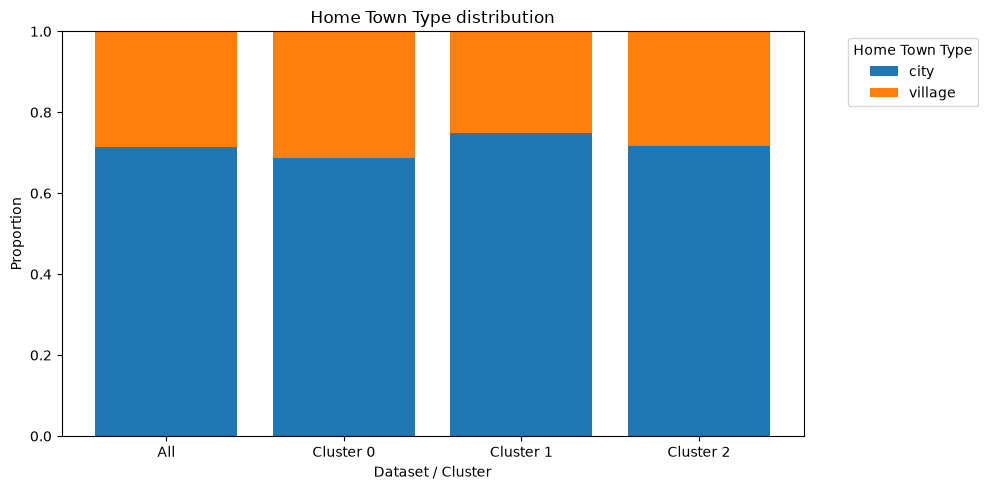

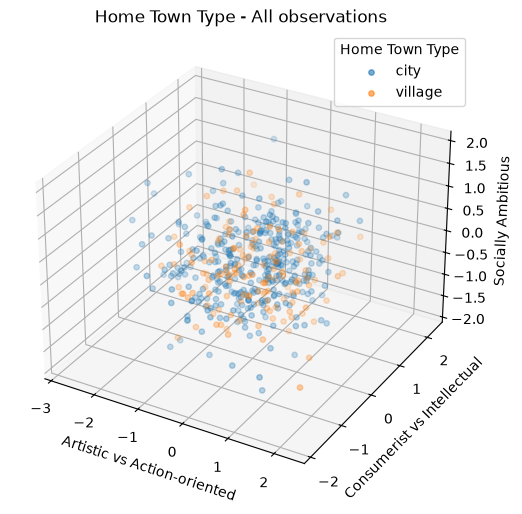

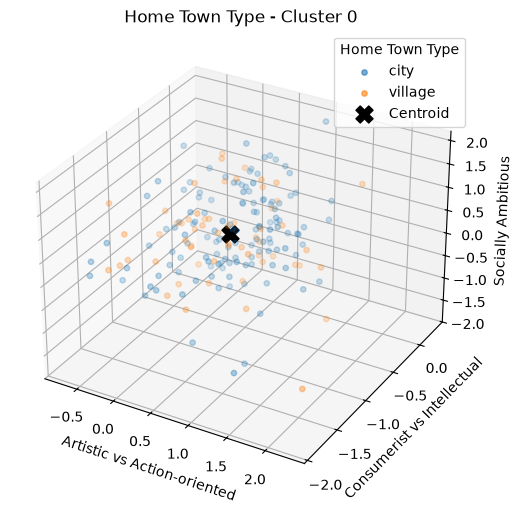

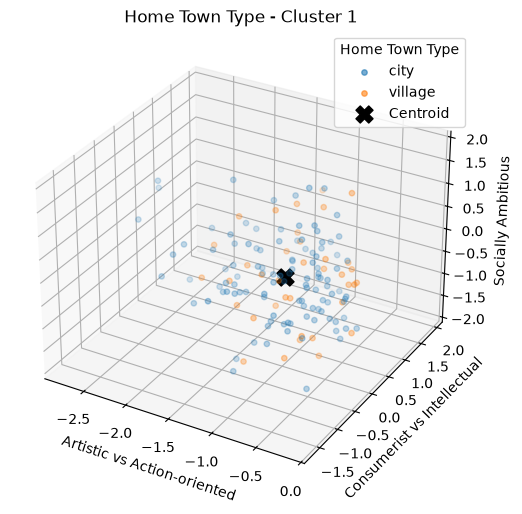

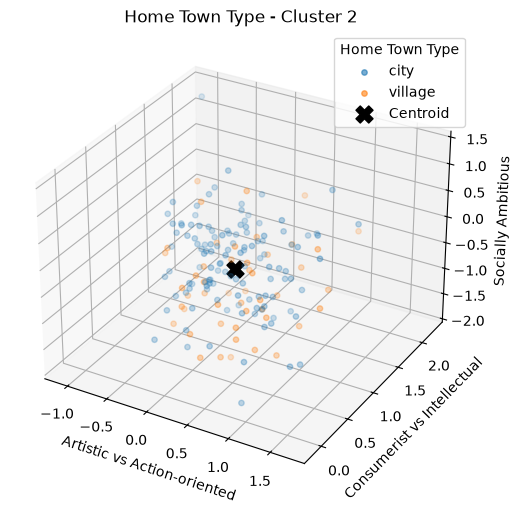

In [13]:

# Selected labels
selected_labels = ['Gender', 'Education', 'Home Town Type']

# Check that rows have the same order
assert responses_lb.index.equals(responses_ft_pp.index)
assert len(responses_lb) == len(km_best.labels_)

for label in selected_labels:

    values = responses_lb[label].astype('string').fillna('Missing')
    categories = sorted(values.unique())

    # Assign a color to each label value
    colors = plt.get_cmap('tab10').colors
    category_colors = {
        cat: colors[i % len(colors)]
        for i, cat in enumerate(categories)
    }

    # 1. Compute label distributions
    distributions = pd.DataFrame(index=categories)

    distributions['All'] = values.value_counts(normalize=True)

    for i in range(best_k):
        distributions[f'Cluster {i}'] = (
            values.iloc[km_best.labels_ == i]
            .value_counts(normalize=True)
        )

    distributions = distributions.fillna(0)

    print(f'Distribution of {label}:')
    display(distributions)

    # 2. Plot distributions
    plt.figure(figsize=(10, 5))

    x = np.arange(best_k + 1)
    bottom = np.zeros(best_k + 1)

    for cat in categories:
        heights = distributions.loc[cat].to_numpy(dtype=float)

        plt.bar(x, heights, bottom=bottom,
                color=category_colors[cat], label=cat)

        bottom += heights

    plt.xticks(x, distributions.columns)
    plt.xlabel('Dataset / Cluster')
    plt.ylabel('Proportion')
    plt.ylim(0, 1)
    plt.title(f'{label} distribution')
    plt.legend(title=label, bbox_to_anchor=(1.05, 1),
               loc='upper left')
    plt.tight_layout()
    plt.show()

    # 3. Score graph of all data and individual clusters
    for cluster in [None] + list(range(best_k)):

        if cluster is None:
            mask = np.ones(len(values), dtype=bool)
            graph_title = 'All observations'
        else:
            mask = km_best.labels_ == cluster
            graph_title = f'Cluster {cluster}'

        fig = plt.figure(figsize=(9, 6))
        ax = fig.add_subplot(111, projection='3d')

        for cat in categories:
            selected = mask & (values.to_numpy() == cat)

            if np.any(selected):
                ax.scatter(
                    responses_ft_pca[selected, 0],
                    responses_ft_pca[selected, 1],
                    responses_ft_pca[selected, 2],
                    color=category_colors[cat],
                    label=cat,
                    alpha=0.6,
                    s=15
                )

        # Add centroid in individual cluster graphs
        if cluster is not None:
            centroid = km_best.cluster_centers_[cluster]

            ax.scatter(
                centroid[0],
                centroid[1],
                centroid[2],
                c='black',
                marker='X',
                s=150,
                label='Centroid'
            )

        ax.set_title(f'{label} - {graph_title}')
        ax.set_xlabel(pc_names[0])
        ax.set_ylabel(pc_names[1])
        ax.set_zlabel(pc_names[2])
        ax.legend(title=label)

        plt.show()


#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

...

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

Cluster 0: 0.1538
Cluster 1: 0.1981
Cluster 2: 0.1901
Overall silhouette score: 0.1790


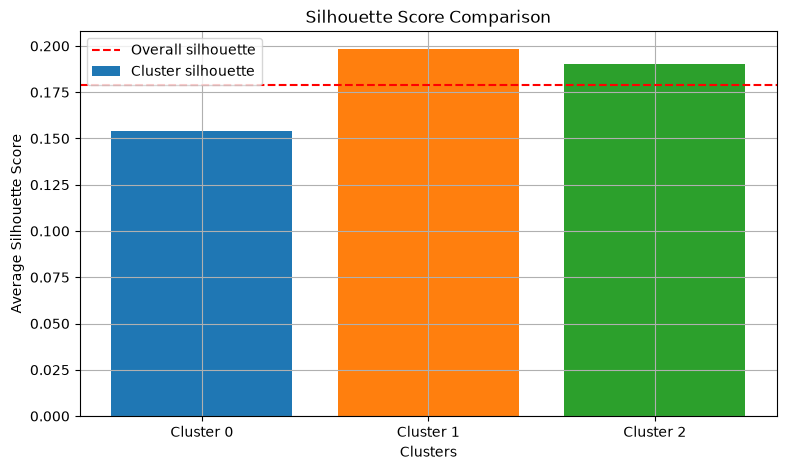

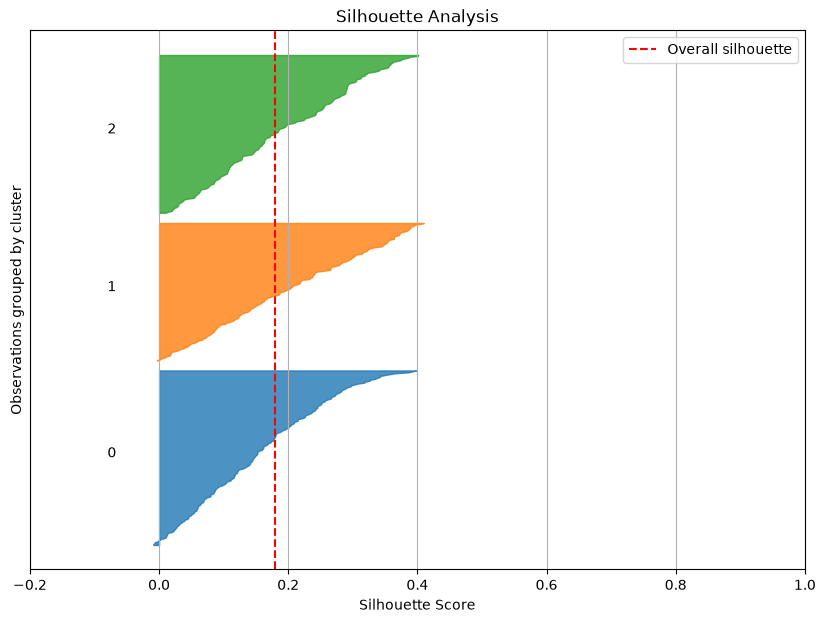

In [14]:
# Compute silhouette scores for each observation
sample_scores = silhouette_samples(
    responses_ft_pca, km_best.labels_ #cluster assigned to each observation
)

# Compute overall silhouette score
overall_score = silhouette_score(
    responses_ft_pca, km_best.labels_
)

# Compute average silhouette score for each cluster
cluster_scores = []

for i in range(best_k):
    score = np.mean(sample_scores[km_best.labels_ == i]) #boolean mask for observation in the i-th cluster
    cluster_scores.append(score)

    print(f'Cluster {i}: {score:.4f}')

print(f'Overall silhouette score: {overall_score:.4f}')


# 1. Plot average silhouette scores
colors = plt.get_cmap('tab10').colors

plt.figure(figsize=(9, 5))

plt.bar(
    np.arange(best_k),
    cluster_scores,
    color=colors[:best_k],
    label='Cluster silhouette'
)

plt.axhline(
    overall_score,
    color='red',
    linestyle='--',
    label='Overall silhouette'
)

plt.xticks(np.arange(best_k),
           [f'Cluster {i}' for i in range(best_k)])

plt.xlabel('Clusters')
plt.ylabel('Average Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.legend()
plt.grid()
plt.show()


# 2. Silhouette plot for each cluster
plt.figure(figsize=(10, 7))

y_lower = 10

for i in range(best_k):

    # Select and sort the silhouette scores
    cluster_sample_scores = sample_scores[km_best.labels_ == i]
    cluster_sample_scores.sort()

    cluster_size = len(cluster_sample_scores)
    y_upper = y_lower + cluster_size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_sample_scores,
        color=colors[i],
        alpha=0.8
    )

    plt.text(-0.08, y_lower + cluster_size / 2, str(i))

    y_lower = y_upper + 10

# Overall silhouette score
plt.axvline(
    overall_score,
    color='red',
    linestyle='--',
    label='Overall silhouette'
)

plt.xlabel('Silhouette Score')
plt.ylabel('Observations grouped by cluster')
plt.title('Silhouette Analysis')
plt.xlim([-0.2, 1])
plt.yticks([])
plt.legend()
plt.grid()
plt.show()


#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

The overall silhouette score is 0.1790, indicating that the clusters are weakly separated. Cluster 1 achieves the highest average silhouette score (0.1981), followed by Cluster 2 (0.1901), while Cluster 0 presents the lowest value (0.1538).

From the silhouette plot, we can observe that almost all observations have positive silhouette scores, although none of them reaches particularly high values. A few negative values suggest potentially inappropriate cluster assignments.

These results are consistent with the overlap observed in the score graph. Although the centroids have meaningful interpretations and are mainly differentiated by PC1 and PC2, the individual observations do not form clearly separated groups.

Furthermore, the five selected PCs preserve only 25.56% of the original variance, which may contribute to the weak separation. Overall, the clustering identifies meaningful profiles of people, but these should be interpreted as general tendencies rather than clearly distinct groups.